In [1]:
print("Hello")

Hello


In [3]:
import scanpy as sc
print("Scanpy loaded:", sc.__version__)

Scanpy loaded: 1.12.4


C:\Users\user\AppData\Local\Temp\ipykernel_6996\2909384363.py:2: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print("Scanpy loaded:", sc.__version__)


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Core libraries loaded successfully!")

Core libraries loaded successfully!


In [5]:
import os

annotation_path = "../data/GSE131907_Lung_Cancer_cell_annotation.txt.gz"

print(os.path.exists(annotation_path))

True


In [6]:
cell_annotation = pd.read_csv(
    annotation_path,
    sep="\t"
)

cell_annotation.head()

,Index,Barcode,Sample,Sample_Origin,Cell_type,Cell_type.refined,Cell_subtype
0,AAACCTGCAAGGTGTG_LUNG_N01,AAACCTGCAAGGTGTG,LUNG_N01,nLung,Myeloid cells,Myeloid cells,mo-Mac
1,AACTCCCGTTCACCTC_LUNG_N01,AACTCCCGTTCACCTC,LUNG_N01,nLung,Myeloid cells,Myeloid cells,mo-Mac
2,AACTCCCTCACGCGGT_LUNG_N01,AACTCCCTCACGCGGT,LUNG_N01,nLung,Myeloid cells,Myeloid cells,mo-Mac
3,AAGGAGCGTGTGCGTC_LUNG_N01,AAGGAGCGTGTGCGTC,LUNG_N01,nLung,Myeloid cells,Myeloid cells,mo-Mac
4,AAGGTTCAGGTACTCT_LUNG_N01,AAGGTTCAGGTACTCT,LUNG_N01,nLung,Myeloid cells,Myeloid cells,mo-Mac


In [7]:
print("Rows, Columns:", cell_annotation.shape)

print("\nSample origins:")
print(cell_annotation["Sample_Origin"].value_counts())

Rows, Columns: (208506, 7)

Sample origins:
Sample_Origin
tLung     45149
nLung     42995
nLN       37446
mBrain    29060
mLN       21479
PE        20304
tL/B      12073
Name: count, dtype: int64


In [8]:
print("Number of unique samples:", cell_annotation["Sample"].nunique())

print("\nTop samples by cell count:")
print(cell_annotation["Sample"].value_counts().head(20))

Number of unique samples: 58

Top samples by cell count:
Sample
LUNG_N20       5798
NS_07          5730
LN_07          5713
LUNG_T31       5578
LUNG_N34       5222
EBUS_28        5182
EBUS_10        5144
EFFUSION_06    4884
NS_13          4845
LUNG_T28       4705
LUNG_N18       4628
LN_12          4618
EFFUSION_13    4441
LN_08          4395
LUNG_T25       4374
LUNG_T19       4361
LUNG_N31       4241
EFFUSION_12    4224
LUNG_T30       4094
LUNG_T20       4021
Name: count, dtype: int64


In [9]:
sample_origin_summary = (
    cell_annotation
    .groupby("Sample_Origin")["Sample"]
    .nunique()
    .sort_values(ascending=False)
)

sample_origin_summary

Sample_Origin
nLung     11
tLung     11
mBrain    10
nLN       10
mLN        7
PE         5
tL/B       4
Name: Sample, dtype: int64

In [10]:
cell_type_counts = cell_annotation["Cell_type"].value_counts()

print("Number of major cell types:", cell_annotation["Cell_type"].nunique())
print("\nCells in each major cell type:")
print(cell_type_counts)

Number of major cell types: 10

Cells in each major cell type:
Cell_type
T lymphocytes        79676
Myeloid cells        42245
Epithelial cells     36467
B lymphocytes        27657
NK cells             11551
Fibroblasts           4172
MAST cells            3396
Endothelial cells     1996
Oligodendrocytes       716
Undetermined           630
Name: count, dtype: int64


In [11]:
lung_cells = cell_annotation[
    cell_annotation["Sample_Origin"].isin(["nLung", "tLung"])
]

cell_type_by_origin = pd.crosstab(
    lung_cells["Cell_type"],
    lung_cells["Sample_Origin"]
)

cell_type_by_origin

Sample_Origin,nLung,tLung
Cell_type,,
B lymphocytes,634,5312
Endothelial cells,1341,655
Epithelial cells,3703,7270
Fibroblasts,1670,1718
MAST cells,1079,1809
Myeloid cells,16672,8794
NK cells,6824,1004
T lymphocytes,11072,18587


In [12]:
cell_type_percent = (
    cell_type_by_origin
    .div(cell_type_by_origin.sum(axis=0), axis=1)
    * 100
)

cell_type_percent.round(2)

Sample_Origin,nLung,tLung
Cell_type,,
B lymphocytes,1.47,11.77
Endothelial cells,3.12,1.45
Epithelial cells,8.61,16.10
Fibroblasts,3.88,3.81
MAST cells,2.51,4.01
Myeloid cells,38.78,19.48
NK cells,15.87,2.22
T lymphocytes,25.75,41.17


In [13]:
sample_cell_counts = pd.crosstab(
    lung_cells["Sample"],
    lung_cells["Cell_type"]
)

sample_cell_percent = (
    sample_cell_counts
    .div(sample_cell_counts.sum(axis=1), axis=0)
    * 100
)

print("Shape:", sample_cell_percent.shape)
sample_cell_percent.round(2)

Shape: (22, 8)


Cell_type,B lymphocytes,Endothelial cells,Epithelial cells,Fibroblasts,MAST cells,Myeloid cells,NK cells,T lymphocytes
Sample,,,,,,,,
LUNG_N01,2.57,1.06,6.23,0.53,7.20,40.89,11.71,29.81
LUNG_N06,1.02,0.32,6.27,0.35,1.06,46.14,5.85,38.99
LUNG_N08,1.78,3.43,8.85,0.59,2.49,39.91,21.80,21.15
LUNG_N09,3.28,2.25,15.19,2.10,4.07,46.32,7.08,19.70
LUNG_N18,1.92,3.82,8.62,3.95,1.77,44.10,6.74,29.06
LUNG_N19,1.24,10.41,4.50,2.20,4.83,29.30,26.90,20.62
LUNG_N20,0.62,1.33,5.26,0.28,2.71,61.14,13.21,15.45
LUNG_N28,1.06,0.32,6.83,0.35,1.67,23.01,19.32,47.43
LUNG_N30,1.44,4.81,8.60,5.92,1.44,24.07,14.96,38.75


In [14]:
sample_cell_percent["Group"] = [
    "Normal" if sample.startswith("LUNG_N") else "Tumor"
    for sample in sample_cell_percent.index
]

sample_cell_percent[["Group"]].T

Sample,LUNG_N01,LUNG_N06,LUNG_N08,LUNG_N09,LUNG_N18,LUNG_N19,LUNG_N20,LUNG_N28,LUNG_N30,LUNG_N31,...,LUNG_T08,LUNG_T09,LUNG_T18,LUNG_T19,LUNG_T20,LUNG_T25,LUNG_T28,LUNG_T30,LUNG_T31,LUNG_T34
Cell_type,,,,,,,,,,,,,,,,,,,,,
Group,Normal,Normal,Normal,Normal,Normal,Normal,Normal,Normal,Normal,Normal,...,Tumor,Tumor,Tumor,Tumor,Tumor,Tumor,Tumor,Tumor,Tumor,Tumor


In [15]:
sample_cell_percent["Group"].value_counts()

Group
Normal    11
Tumor     11
Name: count, dtype: int64

In [16]:
print("Normal samples:")
print(sorted(lung_cells[lung_cells["Sample_Origin"] == "nLung"]["Sample"].unique()))

print("\nTumor samples:")
print(sorted(lung_cells[lung_cells["Sample_Origin"] == "tLung"]["Sample"].unique()))

Normal samples:
['LUNG_N01', 'LUNG_N06', 'LUNG_N08', 'LUNG_N09', 'LUNG_N18', 'LUNG_N19', 'LUNG_N20', 'LUNG_N28', 'LUNG_N30', 'LUNG_N31', 'LUNG_N34']

Tumor samples:
['LUNG_T06', 'LUNG_T08', 'LUNG_T09', 'LUNG_T18', 'LUNG_T19', 'LUNG_T20', 'LUNG_T25', 'LUNG_T28', 'LUNG_T30', 'LUNG_T31', 'LUNG_T34']


In [17]:
cell_annotation.columns.tolist()

['Index',
 'Barcode',
 'Sample',
 'Sample_Origin',
 'Cell_type',
 'Cell_type.refined',
 'Cell_subtype']

In [18]:
normal_ids = {
    sample.replace("LUNG_N", "")
    for sample in lung_cells[lung_cells["Sample_Origin"] == "nLung"]["Sample"].unique()
}

tumor_ids = {
    sample.replace("LUNG_T", "")
    for sample in lung_cells[lung_cells["Sample_Origin"] == "tLung"]["Sample"].unique()
}

matched_ids = sorted(normal_ids & tumor_ids)

print("Matched IDs:", matched_ids)
print("Number of matched pairs:", len(matched_ids))

Matched IDs: ['06', '08', '09', '18', '19', '20', '28', '30', '31', '34']
Number of matched pairs: 10


In [19]:
print("Matched pairs:")
for patient_id in matched_ids:
    print(f"LUNG_N{patient_id}  ↔  LUNG_T{patient_id}")

print("\nUnmatched Normal:", sorted(normal_ids - tumor_ids))
print("Unmatched Tumor:", sorted(tumor_ids - normal_ids))

Matched pairs:
LUNG_N06  ↔  LUNG_T06
LUNG_N08  ↔  LUNG_T08
LUNG_N09  ↔  LUNG_T09
LUNG_N18  ↔  LUNG_T18
LUNG_N19  ↔  LUNG_T19
LUNG_N20  ↔  LUNG_T20
LUNG_N28  ↔  LUNG_T28
LUNG_N30  ↔  LUNG_T30
LUNG_N31  ↔  LUNG_T31
LUNG_N34  ↔  LUNG_T34

Unmatched Normal: ['01']
Unmatched Tumor: ['25']


In [20]:
paired_samples = []

for patient_id in matched_ids:
    paired_samples.extend([
        f"LUNG_N{patient_id}",
        f"LUNG_T{patient_id}"
    ])

paired_cell_percent = sample_cell_percent.loc[paired_samples]

print("Shape:", paired_cell_percent.shape)

Shape: (20, 9)


In [21]:
from scipy.stats import wilcoxon

normal_t = [
    paired_cell_percent.loc[f"LUNG_N{x}", "T lymphocytes"]
    for x in matched_ids
]

tumor_t = [
    paired_cell_percent.loc[f"LUNG_T{x}", "T lymphocytes"]
    for x in matched_ids
]

stat, p_value = wilcoxon(normal_t, tumor_t)

print("Wilcoxon statistic:", stat)
print("P-value:", p_value)

Wilcoxon statistic: 14.0
P-value: 0.193359375


In [22]:
cell_types = [
    col for col in paired_cell_percent.columns
    if col != "Group"
]

print(cell_types)

['B lymphocytes', 'Endothelial cells', 'Epithelial cells', 'Fibroblasts', 'MAST cells', 'Myeloid cells', 'NK cells', 'T lymphocytes']


In [23]:
from scipy.stats import wilcoxon
import pandas as pd

results = []

for cell_type in cell_types:
    normal = [
        paired_cell_percent.loc[f"LUNG_N{x}", cell_type]
        for x in matched_ids
    ]

    tumor = [
        paired_cell_percent.loc[f"LUNG_T{x}", cell_type]
        for x in matched_ids
    ]

    stat, p = wilcoxon(normal, tumor)

    results.append({
        "Cell_type": cell_type,
        "Statistic": stat,
        "P_value": p
    })

results_df = pd.DataFrame(results)

results_df

,Cell_type,Statistic,P_value
0,B lymphocytes,1.0,0.003906
1,Endothelial cells,6.0,0.027344
2,Epithelial cells,15.0,0.232422
3,Fibroblasts,27.0,1.000000
4,MAST cells,15.0,0.232422
5,Myeloid cells,0.0,0.001953
6,NK cells,0.0,0.001953
7,T lymphocytes,14.0,0.193359


In [24]:
from statsmodels.stats.multitest import multipletests

results_df["FDR"] = multipletests(
    results_df["P_value"],
    method="fdr_bh"
)[1]

results_df

,Cell_type,Statistic,P_value,FDR
0,B lymphocytes,1.0,0.003906,0.010417
1,Endothelial cells,6.0,0.027344,0.054688
2,Epithelial cells,15.0,0.232422,0.265625
3,Fibroblasts,27.0,1.000000,1.000000
4,MAST cells,15.0,0.232422,0.265625
5,Myeloid cells,0.0,0.001953,0.007812
6,NK cells,0.0,0.001953,0.007812
7,T lymphocytes,14.0,0.193359,0.265625


In [25]:
paired_cell_percent.groupby("Group")[cell_types].median().T.round(2)

Group,Normal,Tumor
Cell_type,,
B lymphocytes,1.24,7.45
Endothelial cells,2.84,0.68
Epithelial cells,8.61,10.16
Fibroblasts,2.15,2.20
MAST cells,1.72,2.38
Myeloid cells,36.80,22.21
NK cells,14.82,2.11
T lymphocytes,20.89,39.36


In [26]:
plot_data = paired_cell_percent.reset_index().rename(
    columns={"index": "Sample"}
)

plot_data.head()

Cell_type,Sample,B lymphocytes,Endothelial cells,Epithelial cells,Fibroblasts,MAST cells,Myeloid cells,NK cells,T lymphocytes,Group
0,LUNG_N06,1.021486,0.317013,6.269813,0.352237,1.056710,46.143008,5.847129,38.992603,Normal
1,LUNG_T06,15.207239,1.576182,4.232341,14.156451,2.743724,17.162872,1.167542,43.753649,Tumor
2,LUNG_N08,1.775148,3.431953,8.846154,0.591716,2.485207,39.911243,21.804734,21.153846,Normal
3,LUNG_T08,26.932271,0.371846,1.115538,5.471448,2.416999,7.171315,0.584329,55.936255,Tumor
4,LUNG_N09,3.283228,2.254747,15.189873,2.096519,4.074367,46.321203,7.080696,19.699367,Normal


C:\Users\user\AppData\Local\Temp\ipykernel_6996\793756540.py:20: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


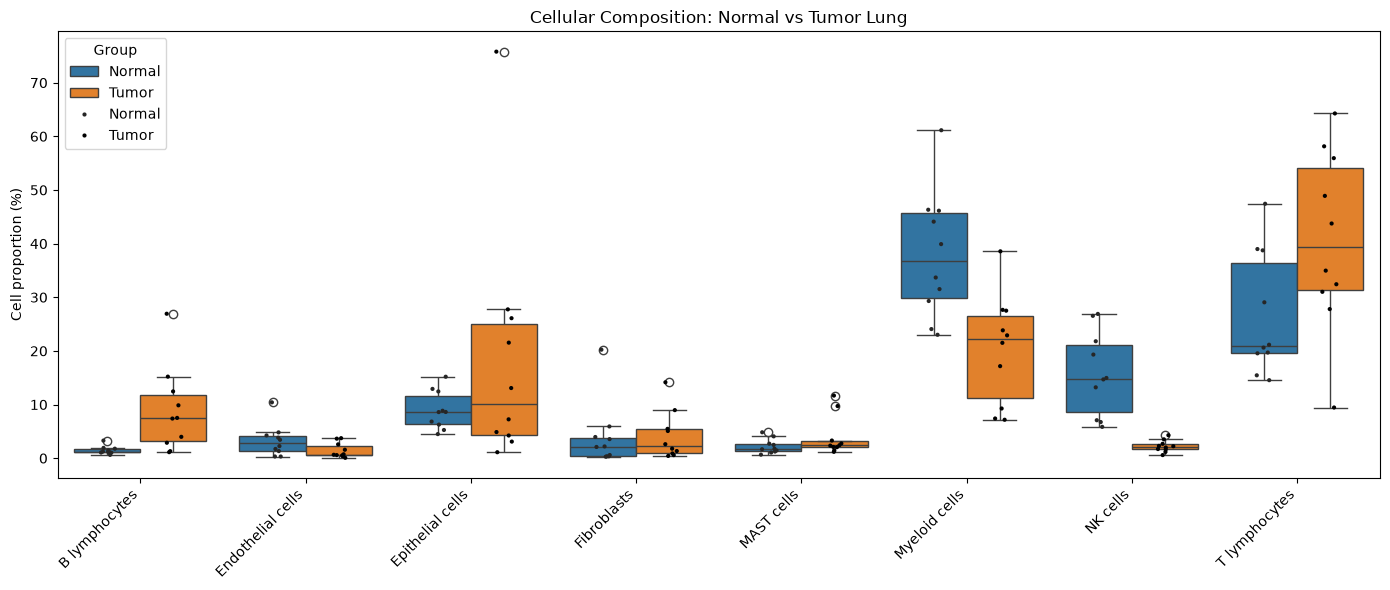

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

plot_long = plot_data.melt(
    id_vars=["Sample", "Group"],
    value_vars=cell_types,
    var_name="Cell_type",
    value_name="Percentage"
)

plt.figure(figsize=(14, 6))

sns.boxplot(
    data=plot_long,
    x="Cell_type",
    y="Percentage",
    hue="Group"
)

sns.stripplot(
    data=plot_long,
    x="Cell_type",
    y="Percentage",
    hue="Group",
    dodge=True,
    color="black",
    size=3
)

plt.xticks(rotation=45, ha="right")
plt.ylabel("Cell proportion (%)")
plt.xlabel("")
plt.title("Cellular Composition: Normal vs Tumor Lung")

plt.tight_layout()
plt.show()

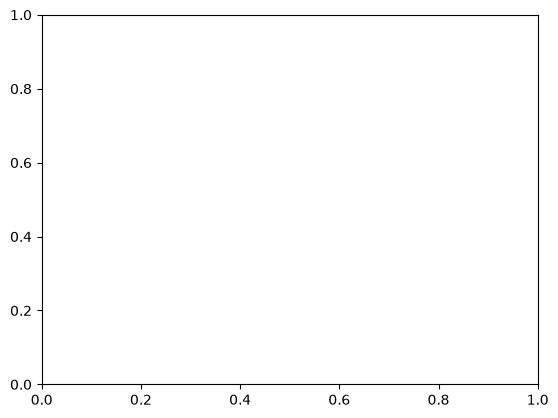

In [28]:
handles, labels = plt.gca().get_legend_handles_labels()

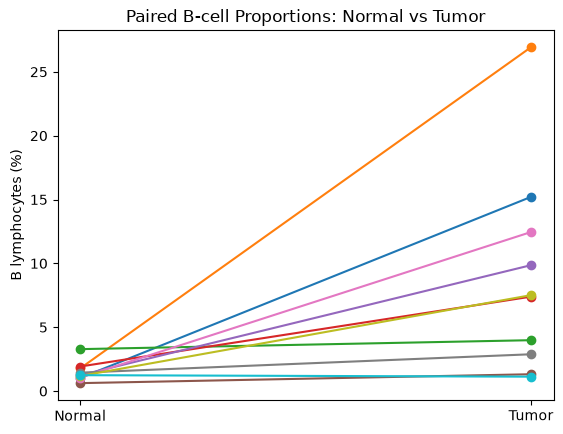

In [29]:
import matplotlib.pyplot as plt

for patient_id in matched_ids:
    normal = paired_cell_percent.loc[
        f"LUNG_N{patient_id}", "B lymphocytes"
    ]
    tumor = paired_cell_percent.loc[
        f"LUNG_T{patient_id}", "B lymphocytes"
    ]

    plt.plot(
        ["Normal", "Tumor"],
        [normal, tumor],
        marker="o"
    )

plt.ylabel("B lymphocytes (%)")
plt.title("Paired B-cell Proportions: Normal vs Tumor")
plt.show()

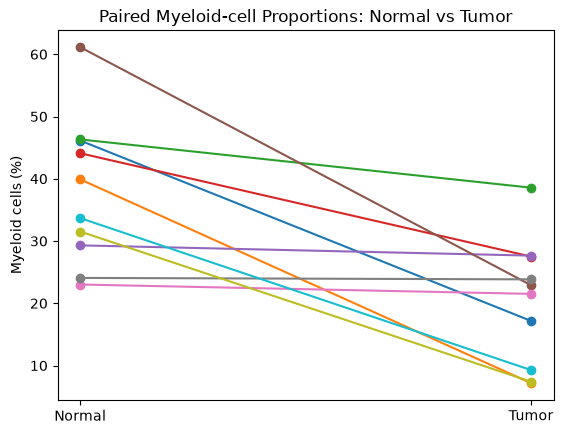

In [30]:
import matplotlib.pyplot as plt

for patient_id in matched_ids:
    normal = paired_cell_percent.loc[
        f"LUNG_N{patient_id}", "Myeloid cells"
    ]
    tumor = paired_cell_percent.loc[
        f"LUNG_T{patient_id}", "Myeloid cells"
    ]

    plt.plot(
        ["Normal", "Tumor"],
        [normal, tumor],
        marker="o"
    )

plt.ylabel("Myeloid cells (%)")
plt.title("Paired Myeloid-cell Proportions: Normal vs Tumor")
plt.show()

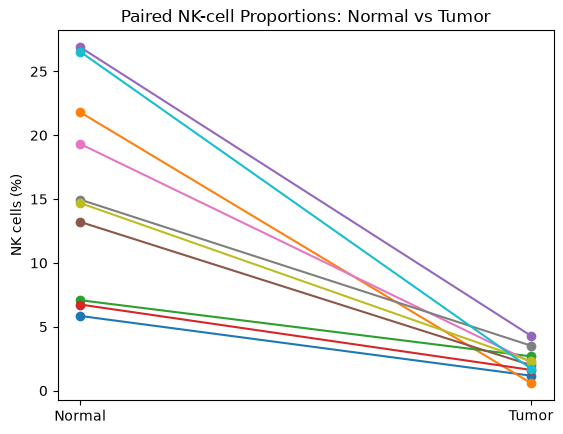

In [31]:
for patient_id in matched_ids:
    normal = paired_cell_percent.loc[
        f"LUNG_N{patient_id}", "NK cells"
    ]
    tumor = paired_cell_percent.loc[
        f"LUNG_T{patient_id}", "NK cells"
    ]

    plt.plot(
        ["Normal", "Tumor"],
        [normal, tumor],
        marker="o"
    )

plt.ylabel("NK cells (%)")
plt.title("Paired NK-cell Proportions: Normal vs Tumor")
plt.show()

In [32]:
import os

os.makedirs("../figures", exist_ok=True)

print("Figures folder ready!")

Figures folder ready!


C:\Users\user\AppData\Local\Temp\ipykernel_6996\3997880707.py:10: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


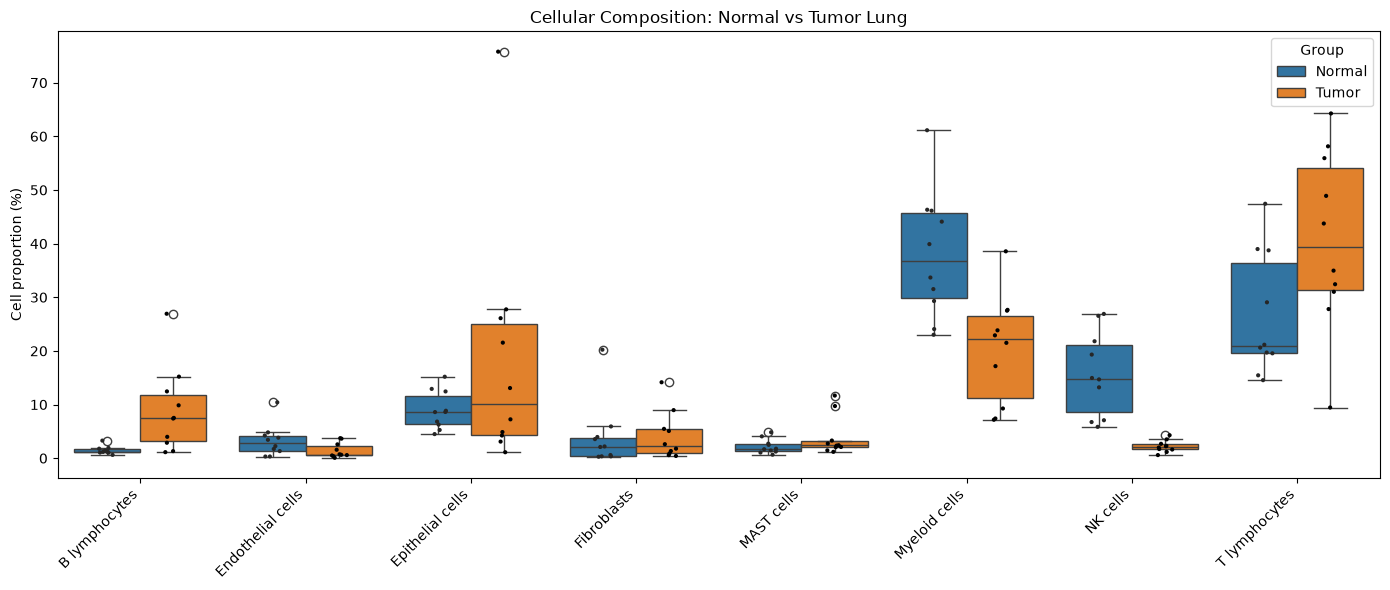

In [33]:
plt.figure(figsize=(14, 6))

sns.boxplot(
    data=plot_long,
    x="Cell_type",
    y="Percentage",
    hue="Group"
)

sns.stripplot(
    data=plot_long,
    x="Cell_type",
    y="Percentage",
    hue="Group",
    dodge=True,
    color="black",
    size=3
)

plt.xticks(rotation=45, ha="right")
plt.ylabel("Cell proportion (%)")
plt.xlabel("")
plt.title("Cellular Composition: Normal vs Tumor Lung")

# Remove duplicate legend
handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(handles[:2], labels[:2], title="Group")

plt.tight_layout()

plt.savefig(
    "../figures/cellular_composition_normal_vs_tumor.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

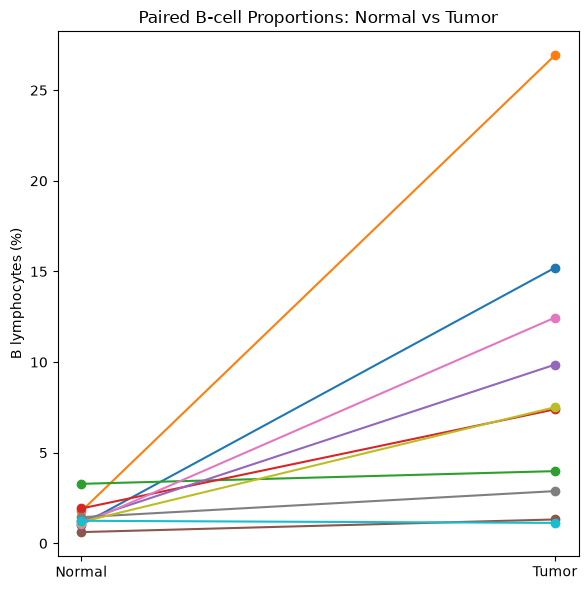

In [34]:
plt.figure(figsize=(6, 6))

for patient_id in matched_ids:
    normal = paired_cell_percent.loc[
        f"LUNG_N{patient_id}", "B lymphocytes"
    ]
    tumor = paired_cell_percent.loc[
        f"LUNG_T{patient_id}", "B lymphocytes"
    ]

    plt.plot(
        ["Normal", "Tumor"],
        [normal, tumor],
        marker="o"
    )

plt.ylabel("B lymphocytes (%)")
plt.title("Paired B-cell Proportions: Normal vs Tumor")
plt.tight_layout()

plt.savefig(
    "../figures/paired_b_cells_normal_vs_tumor.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

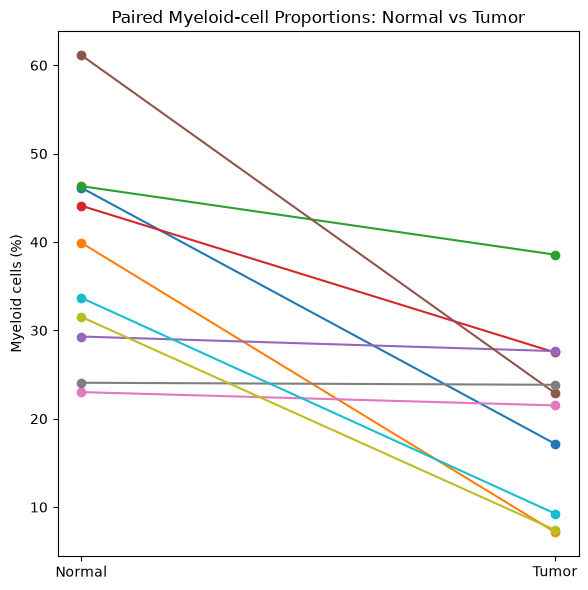

In [35]:
plt.figure(figsize=(6, 6))

for patient_id in matched_ids:
    normal = paired_cell_percent.loc[
        f"LUNG_N{patient_id}", "Myeloid cells"
    ]
    tumor = paired_cell_percent.loc[
        f"LUNG_T{patient_id}", "Myeloid cells"
    ]

    plt.plot(
        ["Normal", "Tumor"],
        [normal, tumor],
        marker="o"
    )

plt.ylabel("Myeloid cells (%)")
plt.title("Paired Myeloid-cell Proportions: Normal vs Tumor")
plt.tight_layout()

plt.savefig(
    "../figures/paired_myeloid_cells_normal_vs_tumor.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

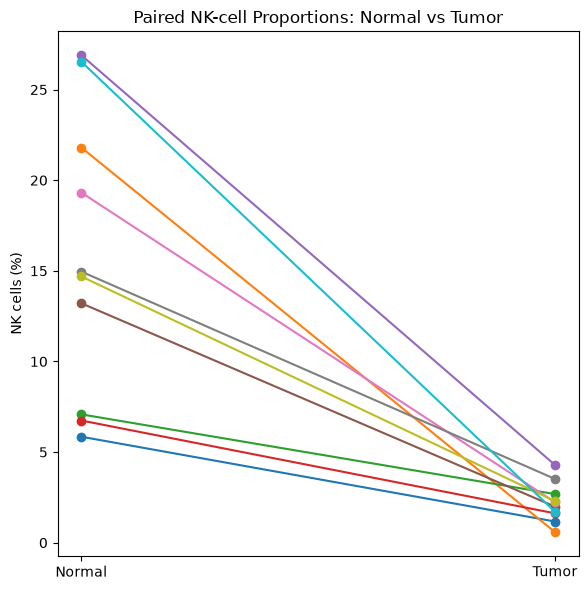

In [36]:
plt.figure(figsize=(6, 6))

for patient_id in matched_ids:
    normal = paired_cell_percent.loc[
        f"LUNG_N{patient_id}", "NK cells"
    ]
    tumor = paired_cell_percent.loc[
        f"LUNG_T{patient_id}", "NK cells"
    ]

    plt.plot(
        ["Normal", "Tumor"],
        [normal, tumor],
        marker="o"
    )

plt.ylabel("NK cells (%)")
plt.title("Paired NK-cell Proportions: Normal vs Tumor")
plt.tight_layout()

plt.savefig(
    "../figures/paired_nk_cells_normal_vs_tumor.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [37]:
print("Number of cell subtypes:",
      lung_cells["Cell_subtype"].nunique())

print("\nCell subtypes:")
print(sorted(lung_cells["Cell_subtype"].dropna().unique()))

Number of cell subtypes: 47

Cell subtypes:
['AT1', 'AT2', 'Activated DCs', 'Alveolar Mac', 'CD141+ DCs', 'CD163+CD14+ DCs', 'CD1c+ DCs', 'CD207+CD1a+ LCs', 'CD4+ Th', 'CD8 low T', 'CD8+/CD4+ Mixed Th', 'COL13A1+ matrix FBs', 'COL14A1+ matrix FBs', 'Ciliated', 'Club', 'Cytotoxic CD8+ T', 'EPCs', 'Exhausted CD8+ T', 'Exhausted Tfh', 'FB-like cells', 'Follicular B cells', 'GC B cells in the DZ', 'GC B cells in the LZ', 'GrB-secreting B cells', 'Lymphatic ECs', 'MALT B cells', 'MAST', 'Mesothelial cells', 'Monocytes', 'Myofibroblasts', 'NK', 'Naive CD4+ T', 'Naive CD8+ T', 'Pericytes', 'Plasma cells', 'Pleural Mac', 'Smooth muscle cells', 'Stalk-like ECs', 'Tip-like ECs', 'Treg', 'Tumor ECs', 'Undetermined', 'mo-Mac', 'pDCs', 'tS1', 'tS2', 'tS3']


In [38]:
myeloid_subtypes = sorted(
    lung_cells.loc[
        lung_cells["Cell_type"] == "Myeloid cells",
        "Cell_subtype"
    ].dropna().unique()
)

print("Number of Myeloid subtypes:", len(myeloid_subtypes))
print(myeloid_subtypes)

Number of Myeloid subtypes: 11
['Activated DCs', 'Alveolar Mac', 'CD141+ DCs', 'CD163+CD14+ DCs', 'CD1c+ DCs', 'CD207+CD1a+ LCs', 'Monocytes', 'Pleural Mac', 'Undetermined', 'mo-Mac', 'pDCs']


In [39]:
myeloid_cells = lung_cells[
    lung_cells["Cell_type"] == "Myeloid cells"
]

myeloid_counts = pd.crosstab(
    myeloid_cells["Cell_subtype"],
    myeloid_cells["Sample_Origin"]
)

myeloid_counts

Sample_Origin,nLung,tLung
Cell_subtype,,
Activated DCs,66,154
Alveolar Mac,12211,1324
CD141+ DCs,101,95
CD163+CD14+ DCs,143,660
CD1c+ DCs,880,528
CD207+CD1a+ LCs,6,87
Monocytes,2319,639
Pleural Mac,67,29
Undetermined,69,484


In [40]:
myeloid_sample_counts = pd.crosstab(
    myeloid_cells["Sample"],
    myeloid_cells["Cell_subtype"]
)

myeloid_sample_percent = (
    myeloid_sample_counts
    .div(myeloid_sample_counts.sum(axis=1), axis=0)
    * 100
)

print("Shape:", myeloid_sample_percent.shape)
myeloid_sample_percent.round(2)

Shape: (22, 11)


Cell_subtype,Activated DCs,Alveolar Mac,CD141+ DCs,CD163+CD14+ DCs,CD1c+ DCs,CD207+CD1a+ LCs,Monocytes,Pleural Mac,Undetermined,mo-Mac,pDCs
Sample,,,,,,,,,,,
LUNG_N01,0.84,46.55,0.84,4.44,5.82,0.00,36.06,0.15,0.00,5.21,0.08
LUNG_N06,0.61,87.48,0.46,0.08,1.91,0.00,7.18,0.08,0.23,1.98,0.00
LUNG_N08,0.37,82.28,0.15,0.59,2.15,0.00,11.42,0.30,0.37,2.37,0.00
LUNG_N09,0.17,80.10,0.51,1.28,4.01,0.00,6.83,0.00,0.09,7.00,0.00
LUNG_N18,0.39,72.86,1.57,0.39,6.52,0.00,11.07,1.22,1.03,4.95,0.00
LUNG_N19,1.06,67.90,0.88,1.32,6.35,0.00,17.20,0.18,0.44,4.59,0.09
LUNG_N20,0.11,91.34,0.03,0.51,4.43,0.11,2.62,0.14,0.11,0.59,0.00
LUNG_N28,0.00,92.74,0.13,0.38,1.27,0.00,3.69,0.13,0.76,0.89,0.00
LUNG_N30,0.32,35.19,0.96,0.43,8.56,0.00,41.50,0.32,1.28,11.44,0.00


In [41]:
paired_myeloid_percent = myeloid_sample_percent.loc[paired_samples]

print("Shape:", paired_myeloid_percent.shape)

Shape: (20, 11)


In [42]:
from scipy.stats import wilcoxon

myeloid_results = []

for subtype in myeloid_subtypes:
    normal = [
        paired_myeloid_percent.loc[f"LUNG_N{x}", subtype]
        for x in matched_ids
    ]

    tumor = [
        paired_myeloid_percent.loc[f"LUNG_T{x}", subtype]
        for x in matched_ids
    ]

    stat, p = wilcoxon(normal, tumor)

    myeloid_results.append({
        "Subtype": subtype,
        "Statistic": stat,
        "P_value": p
    })

myeloid_results_df = pd.DataFrame(myeloid_results)

myeloid_results_df

,Subtype,Statistic,P_value
0,Activated DCs,0.0,0.001953
1,Alveolar Mac,1.0,0.003906
2,CD141+ DCs,9.0,0.064453
3,CD163+CD14+ DCs,0.0,0.001953
4,CD1c+ DCs,22.0,0.625000
5,CD207+CD1a+ LCs,2.0,0.011719
6,Monocytes,6.0,0.027344
7,Pleural Mac,20.0,0.492188
8,Undetermined,0.0,0.001953
9,mo-Mac,1.0,0.003906


In [43]:
from statsmodels.stats.multitest import multipletests

myeloid_results_df["FDR"] = multipletests(
    myeloid_results_df["P_value"],
    method="fdr_bh"
)[1]

myeloid_results_df

,Subtype,Statistic,P_value,FDR
0,Activated DCs,0.0,0.001953,0.005371
1,Alveolar Mac,1.0,0.003906,0.007161
2,CD141+ DCs,9.0,0.064453,0.078776
3,CD163+CD14+ DCs,0.0,0.001953,0.005371
4,CD1c+ DCs,22.0,0.625000,0.625000
5,CD207+CD1a+ LCs,2.0,0.011719,0.018415
6,Monocytes,6.0,0.027344,0.037598
7,Pleural Mac,20.0,0.492188,0.541406
8,Undetermined,0.0,0.001953,0.005371
9,mo-Mac,1.0,0.003906,0.007161


In [44]:
myeloid_group_mean = (
    paired_myeloid_percent
    .assign(Group=[
        "Normal" if "_N" in sample else "Tumor"
        for sample in paired_myeloid_percent.index
    ])
    .groupby("Group")[myeloid_subtypes]
    .mean()
    .T
)

myeloid_group_mean = myeloid_group_mean.round(2)

myeloid_group_mean

Group,Normal,Tumor
Cell_subtype,,
Activated DCs,0.39,1.97
Alveolar Mac,72.83,15.00
CD141+ DCs,0.62,1.16
CD163+CD14+ DCs,0.58,10.24
CD1c+ DCs,5.25,6.18
CD207+CD1a+ LCs,0.03,1.42
Monocytes,13.88,5.97
Pleural Mac,0.40,0.32
Undetermined,0.51,6.61


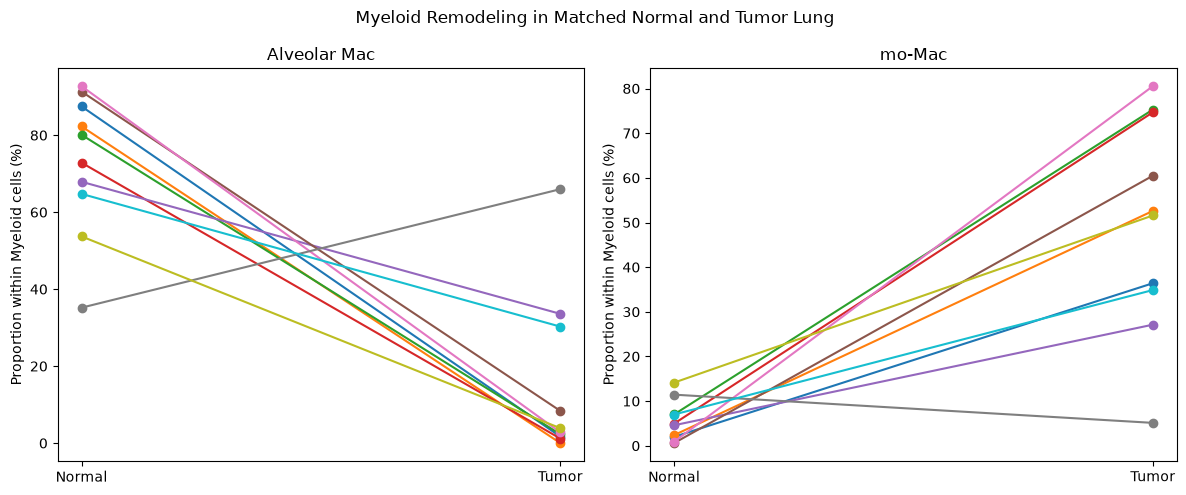

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, subtype in zip(axes, ["Alveolar Mac", "mo-Mac"]):
    for patient_id in matched_ids:
        normal = paired_myeloid_percent.loc[
            f"LUNG_N{patient_id}", subtype
        ]
        tumor = paired_myeloid_percent.loc[
            f"LUNG_T{patient_id}", subtype
        ]

        ax.plot(
            ["Normal", "Tumor"],
            [normal, tumor],
            marker="o"
        )

    ax.set_title(subtype)
    ax.set_ylabel("Proportion within Myeloid cells (%)")

plt.suptitle("Myeloid Remodeling in Matched Normal and Tumor Lung")
plt.tight_layout()

plt.savefig(
    "../results/myeloid_remodeling_alveolar_vs_momac.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [46]:
myeloid_summary = myeloid_group_mean.copy()

myeloid_summary["Change"] = (
    myeloid_summary["Tumor"] - myeloid_summary["Normal"]
)

myeloid_summary = myeloid_summary.merge(
    myeloid_results_df[["Subtype", "FDR"]],
    left_index=True,
    right_on="Subtype"
)

myeloid_summary = myeloid_summary[
    ["Subtype", "Normal", "Tumor", "Change", "FDR"]
]

myeloid_summary

,Subtype,Normal,Tumor,Change,FDR
0,Activated DCs,0.39,1.97,1.58,0.005371
1,Alveolar Mac,72.83,15.00,-57.83,0.007161
2,CD141+ DCs,0.62,1.16,0.54,0.078776
3,CD163+CD14+ DCs,0.58,10.24,9.66,0.005371
4,CD1c+ DCs,5.25,6.18,0.93,0.625000
5,CD207+CD1a+ LCs,0.03,1.42,1.39,0.018415
6,Monocytes,13.88,5.97,-7.91,0.037598
7,Pleural Mac,0.40,0.32,-0.08,0.541406
8,Undetermined,0.51,6.61,6.10,0.005371
9,mo-Mac,5.50,49.86,44.36,0.007161


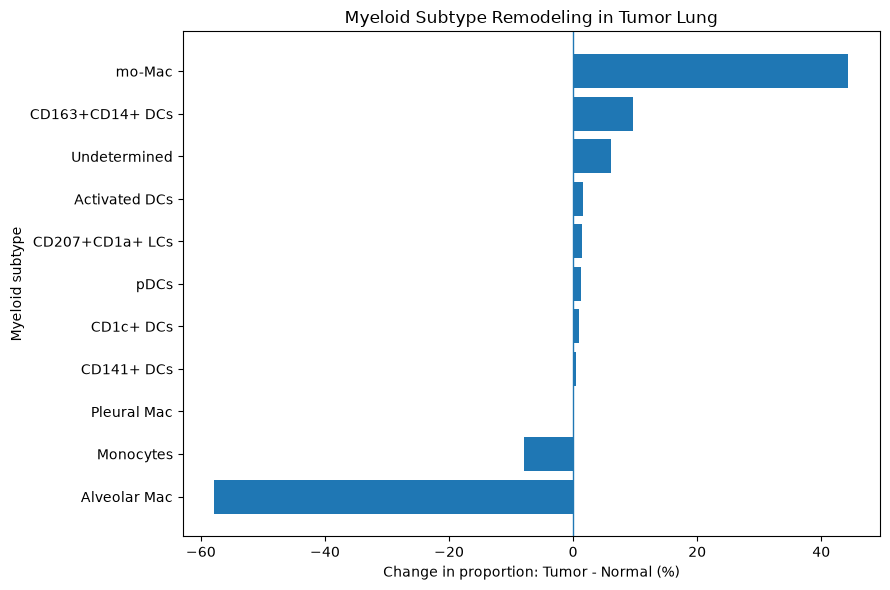

In [47]:
plot_data = myeloid_summary.sort_values("Change")

plt.figure(figsize=(9, 6))

plt.barh(
    plot_data["Subtype"],
    plot_data["Change"]
)

plt.axvline(0, linewidth=1)

plt.xlabel("Change in proportion: Tumor - Normal (%)")
plt.ylabel("Myeloid subtype")
plt.title("Myeloid Subtype Remodeling in Tumor Lung")

plt.tight_layout()

plt.savefig(
    "../results/myeloid_subtype_remodeling_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

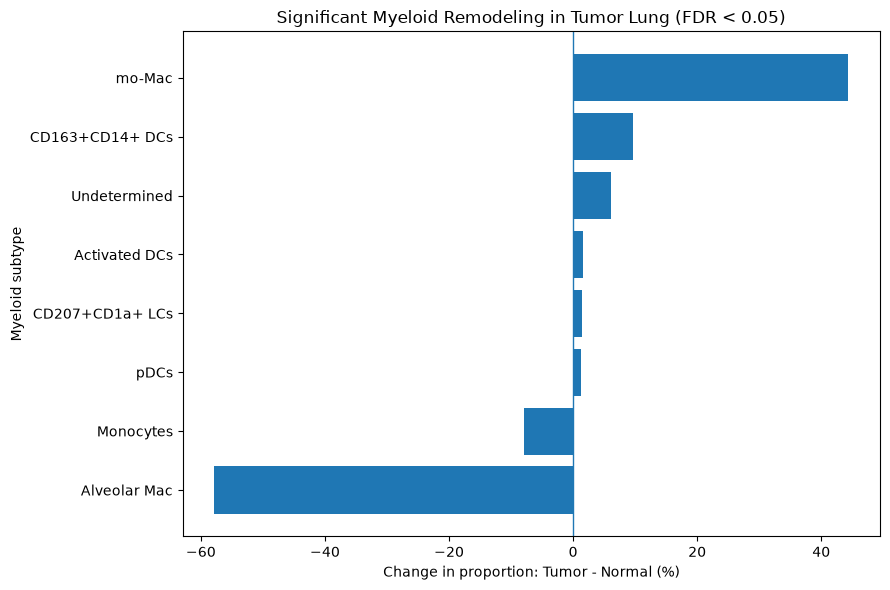

In [48]:
significant_myeloid = myeloid_summary[
    myeloid_summary["FDR"] < 0.05
].copy()

significant_myeloid = significant_myeloid.sort_values("Change")

plt.figure(figsize=(9, 6))

plt.barh(
    significant_myeloid["Subtype"],
    significant_myeloid["Change"]
)

plt.axvline(0, linewidth=1)

plt.xlabel("Change in proportion: Tumor - Normal (%)")
plt.ylabel("Myeloid subtype")
plt.title("Significant Myeloid Remodeling in Tumor Lung (FDR < 0.05)")

plt.tight_layout()

plt.savefig(
    "../results/significant_myeloid_remodeling.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [49]:
bcell_subtypes = sorted(
    lung_cells.loc[
        lung_cells["Cell_type"] == "B lymphocytes",
        "Cell_subtype"
    ].dropna().unique()
)

print("Number of B-cell subtypes:", len(bcell_subtypes))
print(bcell_subtypes)

Number of B-cell subtypes: 7
['Follicular B cells', 'GC B cells in the DZ', 'GC B cells in the LZ', 'GrB-secreting B cells', 'MALT B cells', 'Plasma cells', 'Undetermined']


In [50]:
bcell_cells = lung_cells[
    lung_cells["Cell_type"] == "B lymphocytes"
]

bcell_sample_counts = pd.crosstab(
    bcell_cells["Sample"],
    bcell_cells["Cell_subtype"]
)

bcell_sample_percent = (
    bcell_sample_counts
    .div(bcell_sample_counts.sum(axis=1), axis=0)
    * 100
)

print("Shape:", bcell_sample_percent.shape)
bcell_sample_percent.round(2)

Shape: (22, 7)


Cell_subtype,Follicular B cells,GC B cells in the DZ,GC B cells in the LZ,GrB-secreting B cells,MALT B cells,Plasma cells,Undetermined
Sample,,,,,,,
LUNG_N01,48.78,0.00,0.00,37.80,13.41,0.00,0.00
LUNG_N06,72.41,0.00,0.00,17.24,3.45,3.45,3.45
LUNG_N08,76.67,0.00,0.00,11.67,3.33,6.67,1.67
LUNG_N09,50.60,0.00,0.00,10.84,28.92,9.64,0.00
LUNG_N18,62.92,0.00,0.00,24.72,6.74,2.25,3.37
LUNG_N19,35.42,0.00,0.00,39.58,18.75,6.25,0.00
LUNG_N20,58.33,0.00,0.00,36.11,2.78,0.00,2.78
LUNG_N28,47.22,2.78,0.00,25.00,11.11,5.56,8.33
LUNG_N30,37.50,0.00,0.00,46.43,7.14,3.57,5.36


In [51]:
paired_bcell_percent = bcell_sample_percent.loc[paired_samples]

print("Shape:", paired_bcell_percent.shape)

Shape: (20, 7)


In [52]:
bcell_results = []

for subtype in bcell_subtypes:
    normal = [
        paired_bcell_percent.loc[f"LUNG_N{x}", subtype]
        for x in matched_ids
    ]

    tumor = [
        paired_bcell_percent.loc[f"LUNG_T{x}", subtype]
        for x in matched_ids
    ]

    stat, p = wilcoxon(normal, tumor)

    bcell_results.append({
        "Subtype": subtype,
        "Statistic": stat,
        "P_value": p
    })

bcell_results_df = pd.DataFrame(bcell_results)

bcell_results_df

,Subtype,Statistic,P_value
0,Follicular B cells,20.0,0.492188
1,GC B cells in the DZ,6.0,0.437500
2,GC B cells in the LZ,0.0,0.250000
3,GrB-secreting B cells,0.0,0.001953
4,MALT B cells,8.0,0.048828
5,Plasma cells,17.0,0.322266
6,Undetermined,25.0,0.845703


In [53]:
bcell_results_df["FDR"] = multipletests(
    bcell_results_df["P_value"],
    method="fdr_bh"
)[1]

bcell_results_df

,Subtype,Statistic,P_value,FDR
0,Follicular B cells,20.0,0.492188,0.574219
1,GC B cells in the DZ,6.0,0.437500,0.574219
2,GC B cells in the LZ,0.0,0.250000,0.563965
3,GrB-secreting B cells,0.0,0.001953,0.013672
4,MALT B cells,8.0,0.048828,0.170898
5,Plasma cells,17.0,0.322266,0.563965
6,Undetermined,25.0,0.845703,0.845703


In [54]:
bcell_group_mean = (
    paired_bcell_percent
    .assign(Group=[
        "Normal" if "_N" in sample else "Tumor"
        for sample in paired_bcell_percent.index
    ])
    .groupby("Group")[bcell_subtypes]
    .mean()
    .T
)

bcell_group_mean = bcell_group_mean.round(2)

bcell_summary = bcell_group_mean.copy()

bcell_summary["Change"] = (
    bcell_summary["Tumor"] - bcell_summary["Normal"]
)

bcell_summary = bcell_summary.merge(
    bcell_results_df[["Subtype", "FDR"]],
    left_index=True,
    right_on="Subtype"
)

bcell_summary = bcell_summary[
    ["Subtype", "Normal", "Tumor", "Change", "FDR"]
]

bcell_summary

,Subtype,Normal,Tumor,Change,FDR
0,Follicular B cells,52.55,61.56,9.01,0.574219
1,GC B cells in the DZ,0.28,0.47,0.19,0.574219
2,GC B cells in the LZ,0.00,0.19,0.19,0.563965
3,GrB-secreting B cells,29.33,0.00,-29.33,0.013672
4,MALT B cells,10.70,26.34,15.64,0.170898
5,Plasma cells,3.94,8.04,4.10,0.563965
6,Undetermined,3.20,3.40,0.20,0.845703


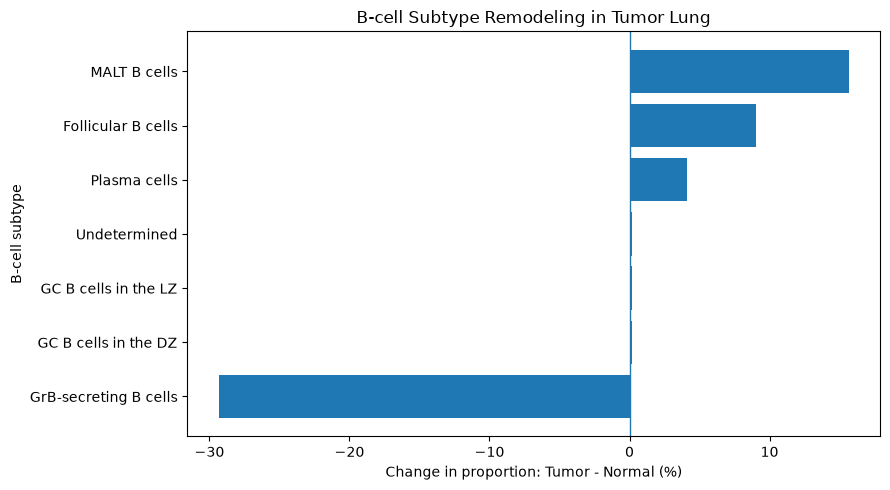

In [55]:
bcell_plot = bcell_summary.sort_values("Change")

plt.figure(figsize=(9, 5))

plt.barh(
    bcell_plot["Subtype"],
    bcell_plot["Change"]
)

plt.axvline(0, linewidth=1)

plt.xlabel("Change in proportion: Tumor - Normal (%)")
plt.ylabel("B-cell subtype")
plt.title("B-cell Subtype Remodeling in Tumor Lung")

plt.tight_layout()

plt.savefig(
    "../results/bcell_subtype_remodeling_all.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

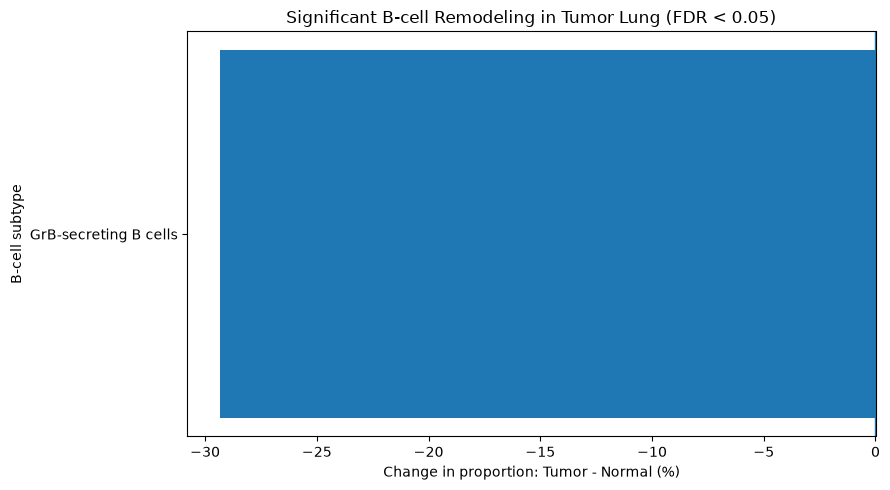

In [56]:
significant_bcell = bcell_summary[
    bcell_summary["FDR"] < 0.05
].copy()

significant_bcell = significant_bcell.sort_values("Change")

plt.figure(figsize=(9, 5))

plt.barh(
    significant_bcell["Subtype"],
    significant_bcell["Change"]
)

plt.axvline(0, linewidth=1)

plt.xlabel("Change in proportion: Tumor - Normal (%)")
plt.ylabel("B-cell subtype")
plt.title("Significant B-cell Remodeling in Tumor Lung (FDR < 0.05)")

plt.tight_layout()

plt.savefig(
    "../results/significant_bcell_remodeling.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [57]:
nk_subtypes = sorted(
    lung_cells.loc[
        lung_cells["Cell_type"] == "NK cells",
        "Cell_subtype"
    ].dropna().unique()
)

print("Number of NK-cell subtypes:", len(nk_subtypes))
print(nk_subtypes)

Number of NK-cell subtypes: 6
['CD4+ Th', 'CD8 low T', 'Cytotoxic CD8+ T', 'Exhausted CD8+ T', 'NK', 'Undetermined']


In [58]:
nk_sample_counts = pd.crosstab(
    lung_cells.loc[
        lung_cells["Cell_type"] == "NK cells",
        "Sample"
    ],
    lung_cells.loc[
        lung_cells["Cell_type"] == "NK cells",
        "Cell_subtype"
    ]
)

nk_sample_percent = (
    nk_sample_counts
    .div(nk_sample_counts.sum(axis=1), axis=0)
    * 100
)

print("Shape:", nk_sample_percent.shape)
nk_sample_percent.round(2)

Shape: (22, 6)


Cell_subtype,CD4+ Th,CD8 low T,Cytotoxic CD8+ T,Exhausted CD8+ T,NK,Undetermined
Sample,,,,,,
LUNG_N01,0.0,0.70,0.35,0.0,97.55,1.40
LUNG_N06,0.0,3.33,0.83,0.0,95.00,0.83
LUNG_N08,0.0,0.27,0.00,0.0,98.93,0.80
LUNG_N09,0.0,0.97,0.00,0.0,99.03,0.00
LUNG_N18,0.0,0.79,2.36,0.0,96.85,0.00
LUNG_N19,0.0,0.00,0.00,0.0,99.22,0.78
LUNG_N20,0.0,0.00,0.00,0.0,99.75,0.25
LUNG_N28,0.0,2.03,0.00,0.0,95.27,2.70
LUNG_N30,0.0,0.80,0.20,0.0,98.40,0.60


In [59]:
paired_normal_samples = [
    "LUNG_N06", "LUNG_N08", "LUNG_N09", "LUNG_N18", "LUNG_N19",
    "LUNG_N20", "LUNG_N28", "LUNG_N30", "LUNG_N31", "LUNG_N34"
]

paired_tumor_samples = [
    "LUNG_T06", "LUNG_T08", "LUNG_T09", "LUNG_T18", "LUNG_T19",
    "LUNG_T20", "LUNG_T28", "LUNG_T30", "LUNG_T31", "LUNG_T34"
]

print(len(paired_normal_samples), len(paired_tumor_samples))

10 10


In [60]:
from scipy.stats import wilcoxon

nk_results = []

for subtype in nk_sample_percent.columns:
    normal = nk_sample_percent.loc[paired_normal_samples, subtype].values
    tumor = nk_sample_percent.loc[paired_tumor_samples, subtype].values

    stat, p = wilcoxon(normal, tumor)

    nk_results.append({
        "Subtype": subtype,
        "Statistic": stat,
        "P_value": p
    })

nk_results_df = pd.DataFrame(nk_results)

nk_results_df

,Subtype,Statistic,P_value
0,CD4+ Th,0.0,1.000000
1,CD8 low T,14.0,0.359375
2,Cytotoxic CD8+ T,1.0,0.031250
3,Exhausted CD8+ T,0.0,1.000000
4,NK,4.0,0.013672
5,Undetermined,13.0,0.546875


In [61]:
from statsmodels.stats.multitest import multipletests

nk_results_df["FDR"] = multipletests(
    nk_results_df["P_value"],
    method="fdr_bh"
)[1]

nk_results_df

,Subtype,Statistic,P_value,FDR
0,CD4+ Th,0.0,1.000000,1.000000
1,CD8 low T,14.0,0.359375,0.718750
2,Cytotoxic CD8+ T,1.0,0.031250,0.093750
3,Exhausted CD8+ T,0.0,1.000000,1.000000
4,NK,4.0,0.013672,0.082031
5,Undetermined,13.0,0.546875,0.820312


In [62]:
nk_group_mean = pd.DataFrame({
    "Normal": nk_sample_percent.loc[paired_normal_samples].mean(),
    "Tumor": nk_sample_percent.loc[paired_tumor_samples].mean()
})

nk_group_mean["Change"] = (
    nk_group_mean["Tumor"] - nk_group_mean["Normal"]
)

nk_summary = nk_group_mean.reset_index().rename(
    columns={"Cell_subtype": "Subtype"}
)

nk_summary = nk_summary.merge(
    nk_results_df[["Subtype", "FDR"]],
    on="Subtype"
)

nk_summary[["Normal", "Tumor", "Change", "FDR"]] = (
    nk_summary[["Normal", "Tumor", "Change", "FDR"]].round(3)
)

nk_summary

,Subtype,Normal,Tumor,Change,FDR
0,CD4+ Th,0.000,0.250,0.250,1.000
1,CD8 low T,0.947,1.715,0.768,0.719
2,Cytotoxic CD8+ T,0.399,5.990,5.591,0.094
3,Exhausted CD8+ T,0.000,0.250,0.250,1.000
4,NK,97.970,91.436,-6.534,0.082
5,Undetermined,0.684,0.359,-0.326,0.820


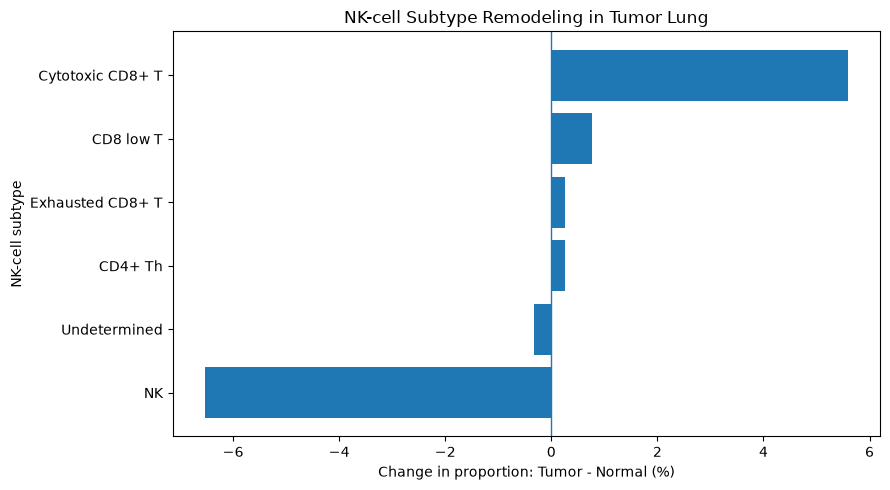

In [63]:
nk_plot = nk_summary.sort_values("Change")

plt.figure(figsize=(9, 5))

plt.barh(
    nk_plot["Subtype"],
    nk_plot["Change"]
)

plt.axvline(0, linewidth=1)

plt.xlabel("Change in proportion: Tumor - Normal (%)")
plt.ylabel("NK-cell subtype")
plt.title("NK-cell Subtype Remodeling in Tumor Lung")

plt.tight_layout()

plt.savefig(
    "../results/nk_subtype_remodeling.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [64]:
import os

for file in os.listdir("../data"):
    print(file)

GSE131907_Lung_Cancer_cell_annotation.txt.gz
GSE131907_Lung_Cancer_raw_UMI_matrix.txt.gz
lung_hvg_expression.h5
lung_normalized_log1p.h5
lung_pca_coordinates.h5
lung_qc_filtered_counts.h5


In [65]:
import gzip

file_path = "../data/GSE131907_Lung_Cancer_raw_UMI_matrix.txt.gz"

with gzip.open(file_path, "rt") as f:
    header = f.readline()

print("Number of columns:", len(header.strip().split("\t")))
print("First 150 characters:", header[:150])

Number of columns: 208507
First 150 characters: Index	AAACCTGAGAAACCGC_LN_05	AAACCTGAGAAACGCC_NS_13	AAACCTGAGAAGGTGA_LUNG_N18	AAACCTGAGACAAAGG_LUNG_N18	AAACCTGAGACATAAC_LN_04	AAACCTGAGACCTTTG_LUNG_N


In [66]:
import gzip

with gzip.open(file_path, "rt") as f:
    header = f.readline()
    first_gene = f.readline()

values = first_gene.strip().split("\t")

print("Gene name:", values[0])
print("First 10 expression values:", values[1:11])
print("Total values:", len(values))

Gene name: A1BG
First 10 expression values: ['0', '0', '0', '0', '0', '0', '0', '0', '0', '0']
Total values: 208507


In [67]:
import numpy as np

counts = np.array(values[1:], dtype=np.int32)

print("Cells with expression:", np.count_nonzero(counts))
print("Maximum UMI count:", counts.max())
print("Total UMI counts:", counts.sum())

Cells with expression: 26441
Maximum UMI count: 32
Total UMI counts: 35957


In [68]:
import gzip

gene_count = 0

with gzip.open(file_path, "rt") as f:
    next(f)  # Skip header

    for line in f:
        gene_count += 1

print("Total genes:", gene_count)

Total genes: 29634


In [69]:
import pandas as pd

annotation = pd.read_csv(
    "../data/GSE131907_Lung_Cancer_cell_annotation.txt.gz",
    sep="\t"
)

lung_annotation = annotation[
    annotation["Sample_Origin"].isin(["nLung", "tLung"])
]

print("Normal cells:", sum(lung_annotation["Sample_Origin"] == "nLung"))
print("Tumor cells:", sum(lung_annotation["Sample_Origin"] == "tLung"))
print("Total selected cells:", len(lung_annotation))

Normal cells: 42995
Tumor cells: 45149
Total selected cells: 88144


In [70]:
matrix_cell_ids = header.strip().split("\t")[1:]

annotation_ids = set(annotation["Index"])

matched = sum(
    cell_id in annotation_ids
    for cell_id in matrix_cell_ids
)

print("Matrix cells:", len(matrix_cell_ids))
print("Matched annotation cells:", matched)
print("Unmatched cells:", len(matrix_cell_ids) - matched)

Matrix cells: 208506
Matched annotation cells: 208506
Unmatched cells: 0


In [71]:
selected_ids = set(lung_annotation["Index"])

selected_positions = [
    i for i, cell_id in enumerate(matrix_cell_ids)
    if cell_id in selected_ids
]

print("Selected columns:", len(selected_positions))
print("First 10 positions:", selected_positions[:10])

Selected columns: 88144
First 10 positions: [2, 3, 5, 6, 7, 8, 10, 11, 13, 14]


In [72]:
selected_counts = counts[selected_positions]

print("Gene:", values[0])
print("Selected cells:", len(selected_counts))
print("Cells expressing gene:", np.count_nonzero(selected_counts))
print("Total UMI counts:", selected_counts.sum())
print("First 10 counts:", selected_counts[:10])

Gene: A1BG
Selected cells: 88144
Cells expressing gene: 11037
Total UMI counts: 14058
First 10 counts: [0 0 0 0 0 0 0 0 1 0]


In [73]:
import psutil

ram = psutil.virtual_memory()

print("Total RAM (GB):", round(ram.total / (1024**3), 2))
print("Available RAM (GB):", round(ram.available / (1024**3), 2))

Total RAM (GB): 15.85
Available RAM (GB): 9.36


In [74]:
import gzip
import numpy as np

gene_names = []
gene_matrix = []

with gzip.open(file_path, "rt") as f:
    next(f)

    for i, line in enumerate(f):
        if i >= 5:
            break

        parts = line.strip().split("\t")

        gene_names.append(parts[0])

        selected = np.array(
            [parts[j + 1] for j in selected_positions],
            dtype=np.int32
        )

        gene_matrix.append(selected)

gene_matrix = np.array(gene_matrix)

print("Genes:", gene_names)
print("Matrix shape:", gene_matrix.shape)

Genes: ['A1BG', 'A1BG-AS1', 'A1CF', 'A2M', 'A2M-AS1']
Matrix shape: (5, 88144)


In [75]:
import os
import shutil

print("D drive exists:", os.path.exists("D:\\"))

total, used, free = shutil.disk_usage("D:\\")

print("Free space (GB):", round(free / (1024**3), 2))

D drive exists: True
Free space (GB): 94.65


In [76]:
import os

output_dir = r"D:\lung_cancer_expression_data"

os.makedirs(output_dir, exist_ok=True)

print("Folder created:", os.path.exists(output_dir))
print("Output location:", output_dir)

Folder created: True
Output location: D:\lung_cancer_expression_data


In [77]:
import h5py

print("HDF5 library ready!")
print("h5py version:", h5py.__version__)

HDF5 library ready!
h5py version: 3.16.0


In [78]:
import h5py
import numpy as np
import os

test_path = os.path.join(output_dir, "test_expression.h5")

with h5py.File(test_path, "w") as f:
    f.create_dataset(
        "counts",
        data=gene_matrix,
        compression="gzip"
    )

print("Test HDF5 created successfully!")
print("File size (MB):", round(os.path.getsize(test_path) / 1024**2, 2))

Test HDF5 created successfully!
File size (MB): 0.07


In [79]:
import h5py
import os

full_path = os.path.join(output_dir, "lung_expression_full.h5")

with h5py.File(full_path, "w") as f:
    f.create_dataset(
        "counts",
        shape=(29634, 88144),
        dtype="int32",
        chunks=(1, 88144),
        compression="gzip"
    )

print("Full HDF5 structure created!")
print("Shape:", (29634, 88144))

Full HDF5 structure created!
Shape: (29634, 88144)


In [80]:
import gzip
import numpy as np
import h5py

with gzip.open(file_path, "rt") as source:
    next(source)  # Skip header

    with h5py.File(full_path, "r+") as destination:
        for i in range(10):
            line = next(source)
            parts = line.rstrip("\n").split("\t")

            selected = np.array(
                [parts[j + 1] for j in selected_positions],
                dtype=np.int32
            )

            destination["counts"][i, :] = selected

print("Successfully saved 10 genes!")

Successfully saved 10 genes!


In [81]:
import gzip
import numpy as np
import h5py
import time

start = time.time()

with gzip.open(file_path, "rt") as source:
    next(source)  # Skip header

    with h5py.File(full_path, "r+") as destination:

        for i, line in enumerate(source):

            if i < 10:
                continue

            parts = line.rstrip("\n").split("\t")

            selected = np.array(
                [parts[j + 1] for j in selected_positions],
                dtype=np.int32
            )

            destination["counts"][i, :] = selected

            if (i + 1) % 500 == 0:
                print(
                    f"Saved {i + 1} / 29634 genes",
                    flush=True
                )

print("All genes saved!")
print("Time (minutes):", round((time.time() - start) / 60, 2))

Saved 500 / 29634 genes
Saved 1000 / 29634 genes
Saved 1500 / 29634 genes
Saved 2000 / 29634 genes
Saved 2500 / 29634 genes
Saved 3000 / 29634 genes
Saved 3500 / 29634 genes
Saved 4000 / 29634 genes
Saved 4500 / 29634 genes
Saved 5000 / 29634 genes
Saved 5500 / 29634 genes
Saved 6000 / 29634 genes
Saved 6500 / 29634 genes
Saved 7000 / 29634 genes
Saved 7500 / 29634 genes
Saved 8000 / 29634 genes
Saved 8500 / 29634 genes
Saved 9000 / 29634 genes
Saved 9500 / 29634 genes
Saved 10000 / 29634 genes
Saved 10500 / 29634 genes
Saved 11000 / 29634 genes
Saved 11500 / 29634 genes
Saved 12000 / 29634 genes
Saved 12500 / 29634 genes
Saved 13000 / 29634 genes
Saved 13500 / 29634 genes
Saved 14000 / 29634 genes
Saved 14500 / 29634 genes
Saved 15000 / 29634 genes
Saved 15500 / 29634 genes
Saved 16000 / 29634 genes
Saved 16500 / 29634 genes
Saved 17000 / 29634 genes
Saved 17500 / 29634 genes
Saved 18000 / 29634 genes
Saved 18500 / 29634 genes
Saved 19000 / 29634 genes
Saved 19500 / 29634 genes
Saved 

In [82]:
import h5py
import os
import numpy as np

with h5py.File(full_path, "r") as f:
    matrix = f["counts"]

    print("Matrix shape:", matrix.shape)
    print("Data type:", matrix.dtype)
    print("First gene UMI total:", np.sum(matrix[0, :]))
    print("Last gene UMI total:", np.sum(matrix[-1, :]))

print("File size (GB):", round(os.path.getsize(full_path) / 1024**3, 2))

Matrix shape: (29634, 88144)
Data type: int32
First gene UMI total: 14058
Last gene UMI total: 4
File size (GB): 0.22


In [83]:
import gzip
import h5py
import numpy as np

check_rows = [0, 100, 1000, 10000, 29633]

with gzip.open(file_path, "rt") as source:
    next(source)

    with h5py.File(full_path, "r") as destination:
        for i, line in enumerate(source):
            if i not in check_rows:
                continue

            parts = line.rstrip("\n").split("\t")

            original = np.array(
                [parts[j + 1] for j in selected_positions],
                dtype=np.int32
            )

            saved = destination["counts"][i, :]

            print(
                parts[0],
                "Matched:",
                np.array_equal(original, saved)
            )

            if i == check_rows[-1]:
                break

A1BG Matched: True
ABHD15-AS1 Matched: True
AC092675.3 Matched: True
HEXA-AS1 Matched: True
bP-2189O9.3 Matched: True


In [84]:
import h5py

selected_cell_ids = [
    matrix_cell_ids[i]
    for i in selected_positions
]

with h5py.File(full_path, "r+") as f:
    if "cell_ids" not in f:
        f.create_dataset(
            "cell_ids",
            data=selected_cell_ids,
            dtype=h5py.string_dtype("utf-8")
        )

print("Cell IDs saved:", len(selected_cell_ids))

Cell IDs saved: 88144


In [85]:
import gzip
import h5py

gene_ids = []

with gzip.open(file_path, "rt") as f:
    next(f)  # Skip header

    for line in f:
        gene_ids.append(line.split("\t", 1)[0])

with h5py.File(full_path, "r+") as f:
    if "gene_ids" not in f:
        f.create_dataset(
            "gene_ids",
            data=gene_ids,
            dtype=h5py.string_dtype("utf-8")
        )

print("Gene IDs saved:", len(gene_ids))
print("First 5 genes:", gene_ids[:5])

Gene IDs saved: 29634
First 5 genes: ['A1BG', 'A1BG-AS1', 'A1CF', 'A2M', 'A2M-AS1']


In [86]:
mt_genes = [
    gene for gene in gene_ids
    if gene.upper().startswith("MT-")
]

print("Mitochondrial genes found:", len(mt_genes))
print("Mitochondrial genes:", mt_genes)

Mitochondrial genes found: 13
Mitochondrial genes: ['MT-ATP6', 'MT-ATP8', 'MT-CO1', 'MT-CO2', 'MT-CO3', 'MT-CYB', 'MT-ND1', 'MT-ND2', 'MT-ND3', 'MT-ND4', 'MT-ND4L', 'MT-ND5', 'MT-ND6']


In [87]:
mt_positions = [
    i for i, gene in enumerate(gene_ids)
    if gene.upper().startswith("MT-")
]

print("Mitochondrial gene positions:", mt_positions)
print("Total:", len(mt_positions))

Mitochondrial gene positions: [14201, 14202, 14203, 14204, 14205, 14206, 14207, 14208, 14209, 14210, 14211, 14212, 14213]
Total: 13


In [88]:
import h5py
import numpy as np

with h5py.File(full_path, "r") as f:
    mt_counts = np.zeros(88144, dtype=np.int64)

    for pos in mt_positions:
        mt_counts += f["counts"][pos, :]

print("Total cells:", len(mt_counts))
print("First 10 mitochondrial UMI counts:", mt_counts[:10])
print("Maximum mitochondrial UMI count:", mt_counts.max())

Total cells: 88144
First 10 mitochondrial UMI counts: [ 106  133  113  408  241   10   68 3172  123  458]
Maximum mitochondrial UMI count: 12405


In [89]:
import h5py
import numpy as np

total_counts = np.zeros(88144, dtype=np.int64)

with h5py.File(full_path, "r") as f:
    matrix = f["counts"]

    for i in range(matrix.shape[0]):
        total_counts += matrix[i, :]

        if (i + 1) % 5000 == 0:
            print(f"Processed {i + 1} genes", flush=True)

print("First 10 total UMI counts:", total_counts[:10])
print("Maximum total UMI count:", total_counts.max())

Processed 5000 genes
Processed 10000 genes
Processed 15000 genes
Processed 20000 genes
Processed 25000 genes
First 10 total UMI counts: [ 3214  2990  2565 10807  4507  5309  2406 38391  5095  9094]
Maximum total UMI count: 110300


In [90]:
mt_percent = np.divide(
    mt_counts * 100,
    total_counts,
    out=np.zeros(len(total_counts), dtype=float),
    where=total_counts > 0
)

print("First 10 MT percentages:", np.round(mt_percent[:10], 2))
print("Mean MT percentage:", round(mt_percent.mean(), 2))
print("Maximum MT percentage:", round(mt_percent.max(), 2))

First 10 MT percentages: [3.3  4.45 4.41 3.78 5.35 0.19 2.83 8.26 2.41 5.04]
Mean MT percentage: 4.56
Maximum MT percentage: 19.99


In [91]:
print("Cells above 5%:", np.sum(mt_percent > 5))
print("Cells above 10%:", np.sum(mt_percent > 10))
print("Cells above 15%:", np.sum(mt_percent > 15))
print("Cells above 20%:", np.sum(mt_percent > 20))

print("Median MT percentage:", np.median(mt_percent))

Cells above 5%: 28903
Cells above 10%: 4008
Cells above 15%: 1140
Cells above 20%: 0
Median MT percentage: 4.045015348407318


In [92]:
import pandas as pd

qc_df = pd.DataFrame({
    "Cell_ID": selected_cell_ids,
    "MT_Percent": mt_percent,
    "Total_UMI": total_counts
})

qc_df = qc_df.merge(
    lung_annotation[["Index", "Sample_Origin"]],
    left_on="Cell_ID",
    right_on="Index",
    how="left",
    validate="one_to_one"
)

print(
    qc_df.groupby("Sample_Origin")["MT_Percent"]
    .agg(["count", "mean", "median", "max"])
    .round(2)
)

               count  mean  median    max
Sample_Origin                            
nLung          42995  5.01    4.54  19.98
tLung          45149  4.12    3.52  19.99


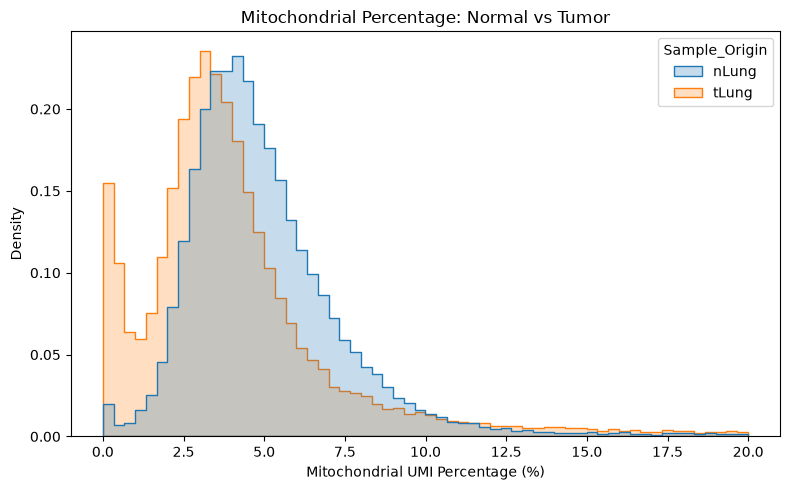

In [93]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(
    data=qc_df,
    x="MT_Percent",
    hue="Sample_Origin",
    bins=60,
    stat="density",
    common_norm=False,
    element="step"
)

plt.xlabel("Mitochondrial UMI Percentage (%)")
plt.ylabel("Density")
plt.title("Mitochondrial Percentage: Normal vs Tumor")

plt.tight_layout()
plt.savefig("../figures/mt_percentage_distribution.png", dpi=300)
plt.show()

In [94]:
import h5py
import numpy as np

detected_genes = np.zeros(88144, dtype=np.int32)

with h5py.File(full_path, "r") as f:
    matrix = f["counts"]

    for i in range(matrix.shape[0]):
        detected_genes += (matrix[i, :] > 0)

        if (i + 1) % 5000 == 0:
            print(f"Processed {i + 1} genes", flush=True)

print("Minimum detected genes:", detected_genes.min())
print("Median detected genes:", np.median(detected_genes))
print("Maximum detected genes:", detected_genes.max())
print("First 10 cells:", detected_genes[:10])

Processed 5000 genes
Processed 10000 genes
Processed 15000 genes
Processed 20000 genes
Processed 25000 genes
Minimum detected genes: 200
Median detected genes: 1167.0
Maximum detected genes: 8905
First 10 cells: [1113 1100  847 2348 1313  915 1210 5957 1283 1942]


In [95]:
qc_df["Detected_Genes"] = detected_genes

print(
    qc_df.groupby("Sample_Origin")[
        ["Total_UMI", "Detected_Genes", "MT_Percent"]
    ].median().round(2)
)

print("\nTotal cells:", len(qc_df))
print("Missing values:")
print(
    qc_df[
        ["Total_UMI", "Detected_Genes", "MT_Percent"]
    ].isna().sum()
)

               Total_UMI  Detected_Genes  MT_Percent
Sample_Origin                                       
nLung             3557.0          1236.0        4.54
tLung             3419.0          1107.0        3.52

Total cells: 88144
Missing values:
Total_UMI         0
Detected_Genes    0
MT_Percent        0
dtype: int64


In [96]:
qc_df["Pass_QC"] = (
    (qc_df["Detected_Genes"] >= 300) &
    (qc_df["Total_UMI"] >= 500) &
    (qc_df["MT_Percent"] <= 15)
)

print("Total cells:", len(qc_df))
print("Cells passing QC:", qc_df["Pass_QC"].sum())
print("Cells failing QC:", (~qc_df["Pass_QC"]).sum())

print("\nQC results by group:")
print(
    qc_df.groupby("Sample_Origin")["Pass_QC"]
    .agg(["count", "sum", "mean"])
    .round(3)
)

Total cells: 88144
Cells passing QC: 86756
Cells failing QC: 1388

QC results by group:
               count    sum   mean
Sample_Origin                     
nLung          42995  42574  0.990
tLung          45149  44182  0.979


In [97]:
print("Low detected genes:",
      (qc_df["Detected_Genes"] < 300).sum())

print("Low UMI:",
      (qc_df["Total_UMI"] < 500).sum())

print("High mitochondrial percentage:",
      (qc_df["MT_Percent"] > 15).sum())

Low detected genes: 251
Low UMI: 0
High mitochondrial percentage: 1140


In [98]:
print(qc_df.columns.tolist())

['Cell_ID', 'MT_Percent', 'Total_UMI', 'Index', 'Sample_Origin', 'Detected_Genes', 'Pass_QC']


In [99]:
qc_df["QC_Fail"] = ~qc_df["Pass_QC"]

qc_df["Sample"] = qc_df["Cell_ID"].str.split("_").str[-2:].str.join("_")

sample_qc = qc_df.groupby("Sample").agg(
    Total_Cells=("QC_Fail", "size"),
    Failed_Cells=("QC_Fail", "sum")
)

sample_qc["Fail_Percent"] = (
    sample_qc["Failed_Cells"] /
    sample_qc["Total_Cells"] * 100
)

print(
    sample_qc.sort_values(
        "Fail_Percent", ascending=False
    ).head(10).round(2)
)

          Total_Cells  Failed_Cells  Fail_Percent
Sample                                           
LUNG_T18         3705           266          7.18
LUNG_T34         3280           161          4.91
LUNG_T28         4705           141          3.00
LUNG_T31         5578           150          2.69
LUNG_N18         4628            57          1.23
LUNG_N09         2528            30          1.19
LUNG_N08         3380            39          1.15
LUNG_N28         3411            39          1.14
LUNG_T20         4021            45          1.12
LUNG_T08         3765            41          1.09


In [100]:
t18 = qc_df[qc_df["Sample"] == "LUNG_T18"]

print("Total cells:", len(t18))

print("Low detected genes:",
      (t18["Detected_Genes"] < 300).sum())

print("Low UMI:",
      (t18["Total_UMI"] < 500).sum())

print("High mitochondrial percentage:",
      (t18["MT_Percent"] > 15).sum())

print("QC failed cells:",
      (~t18["Pass_QC"]).sum())

Total cells: 3705
Low detected genes: 3
Low UMI: 0
High mitochondrial percentage: 264
QC failed cells: 266


In [101]:
high_mt_t18 = t18[t18["MT_Percent"] > 15]

print("High MT cells:", len(high_mt_t18))

print(
    high_mt_t18[
        ["MT_Percent", "Total_UMI", "Detected_Genes"]
    ].describe().round(2)
)

High MT cells: 264
       MT_Percent  Total_UMI  Detected_Genes
count      264.00     264.00          264.00
mean        17.23   13547.29         3105.03
std          1.44    9158.11         1409.14
min         15.01    1008.00          283.00
25%         15.89    7001.25         2187.75
50%         17.00   12636.50         3145.00
75%         18.39   18042.50         3926.25
max         19.97   54565.00         7193.00


In [102]:
for threshold in [10, 12, 15, 18, 20]:
    passed = (
        (qc_df["Detected_Genes"] >= 300) &
        (qc_df["Total_UMI"] >= 500) &
        (qc_df["MT_Percent"] <= threshold)
    )

    print(
        f"MT <= {threshold}%:",
        passed.sum(),
        "cells retained"
    )

MT <= 10%: 83893 cells retained
MT <= 12%: 85574 cells retained
MT <= 15%: 86756 cells retained
MT <= 18%: 87506 cells retained
MT <= 20%: 87893 cells retained


In [103]:
high_mt_ids = set(
    qc_df.loc[
        qc_df["MT_Percent"] > 15,
        "Cell_ID"
    ]
)

high_mt_annotation = lung_annotation[
    lung_annotation["Index"].isin(high_mt_ids)
]

print("Matched high-MT cells:", len(high_mt_annotation))

print(
    high_mt_annotation["Cell_type"].value_counts()
)

Matched high-MT cells: 1140
Cell_type
Epithelial cells     738
Myeloid cells        268
T lymphocytes         43
Fibroblasts           36
B lymphocytes         21
Endothelial cells     19
NK cells              10
MAST cells             5
Name: count, dtype: int64


In [104]:
all_counts = lung_annotation["Cell_type"].value_counts()

high_counts = high_mt_annotation["Cell_type"].value_counts()

mt_rate = (
    high_counts.div(all_counts)
    .mul(100)
    .fillna(0)
    .sort_values(ascending=False)
)

print(mt_rate.round(2))

Cell_type
Epithelial cells     6.73
Fibroblasts          1.06
Myeloid cells        1.05
Endothelial cells    0.95
B lymphocytes        0.35
MAST cells           0.17
T lymphocytes        0.14
NK cells             0.13
Name: count, dtype: float64


In [105]:
epithelial_mt = high_mt_annotation[
    high_mt_annotation["Cell_type"] == "Epithelial cells"
]

print(
    epithelial_mt["Sample_Origin"].value_counts()
)

Sample_Origin
tLung    599
nLung    139
Name: count, dtype: int64


In [106]:
epithelial_all = lung_annotation[
    lung_annotation["Cell_type"] == "Epithelial cells"
]

total_epi = epithelial_all["Sample_Origin"].value_counts()

high_epi = epithelial_mt["Sample_Origin"].value_counts()

epi_mt_rate = (high_epi / total_epi * 100).round(2)

print("Total epithelial cells:")
print(total_epi)

print("\nHigh-MT epithelial percentage:")
print(epi_mt_rate)

Total epithelial cells:
Sample_Origin
tLung    7270
nLung    3703
Name: count, dtype: int64

High-MT epithelial percentage:
Sample_Origin
tLung    8.24
nLung    3.75
Name: count, dtype: float64


In [107]:
epi_total_sample = epithelial_all.groupby("Sample").size()

epi_high_sample = epithelial_mt.groupby("Sample").size()

epi_sample_rate = (
    epi_high_sample
    .reindex(epi_total_sample.index, fill_value=0)
    / epi_total_sample * 100
)

print(epi_sample_rate.round(2))

Sample
LUNG_N01     2.51
LUNG_N06     3.37
LUNG_N08     4.68
LUNG_N09     3.12
LUNG_N18     5.76
LUNG_N19     2.87
LUNG_N20     5.25
LUNG_N28     2.58
LUNG_N30     2.10
LUNG_N31     3.47
LUNG_N34     4.00
LUNG_T06     8.28
LUNG_T08    38.10
LUNG_T09     4.20
LUNG_T18    24.22
LUNG_T19     3.48
LUNG_T20     5.51
LUNG_T25     3.98
LUNG_T28     6.76
LUNG_T30     1.47
LUNG_T31     5.88
LUNG_T34     6.28
dtype: float64


In [108]:
normal_rates = epi_sample_rate[
    epi_sample_rate.index.str.startswith("LUNG_N")
]

tumor_rates = epi_sample_rate[
    epi_sample_rate.index.str.startswith("LUNG_T")
]

tumor_without_outliers = tumor_rates.drop(
    ["LUNG_T08", "LUNG_T18"]
)

print("Normal mean:", round(normal_rates.mean(), 2))
print("Tumor mean:", round(tumor_rates.mean(), 2))
print(
    "Tumor without T08 and T18:",
    round(tumor_without_outliers.mean(), 2)
)

Normal mean: 3.61
Tumor mean: 9.83
Tumor without T08 and T18: 5.09


In [109]:
paired_ids = [
    "06", "08", "09", "18", "19",
    "20", "28", "30", "31", "34"
]

for pid in paired_ids:
    normal = epi_sample_rate[f"LUNG_N{pid}"]
    tumor = epi_sample_rate[f"LUNG_T{pid}"]

    print(
        pid,
        "Normal:", round(normal, 2),
        "Tumor:", round(tumor, 2),
        "Difference:", round(tumor - normal, 2)
    )

06 Normal: 3.37 Tumor: 8.28 Difference: 4.91
08 Normal: 4.68 Tumor: 38.1 Difference: 33.41
09 Normal: 3.12 Tumor: 4.2 Difference: 1.08
18 Normal: 5.76 Tumor: 24.22 Difference: 18.46
19 Normal: 2.87 Tumor: 3.48 Difference: 0.61
20 Normal: 5.25 Tumor: 5.51 Difference: 0.27
28 Normal: 2.58 Tumor: 6.76 Difference: 4.18
30 Normal: 2.1 Tumor: 1.47 Difference: -0.62
31 Normal: 3.47 Tumor: 5.88 Difference: 2.42
34 Normal: 4.0 Tumor: 6.28 Difference: 2.28


In [110]:
from scipy.stats import wilcoxon

normal_values = [
    epi_sample_rate[f"LUNG_N{pid}"]
    for pid in paired_ids
]

tumor_values = [
    epi_sample_rate[f"LUNG_T{pid}"]
    for pid in paired_ids
]

stat, p_value = wilcoxon(
    tumor_values,
    normal_values
)

print("Wilcoxon statistic:", stat)
print("P-value:", p_value)

Wilcoxon statistic: 3.0
P-value: 0.009765625


In [111]:
import os

os.makedirs("../results", exist_ok=True)

qc_df.to_csv(
    "../results/lung_cell_qc_metrics.csv",
    index=False
)

print("QC metrics saved successfully!")
print("Total cells:", len(qc_df))

QC metrics saved successfully!
Total cells: 88144


In [112]:
passed_cell_ids = set(
    qc_df.loc[
        qc_df["Pass_QC"],
        "Cell_ID"
    ]
)

print("QC-passed cell IDs:", len(passed_cell_ids))
print("First 5 IDs:", list(passed_cell_ids)[:5])

QC-passed cell IDs: 86756
First 5 IDs: ['ACTGAACGTTCCACAA_LUNG_N31', 'CGAATGTGTCATTAGC_LUNG_N06', 'CTCGAGGAGAGAACAG_LUNG_N20', 'AGGGTGAAGAGCCCAA_LUNG_T06', 'GTGCTTCGTACGACCC_LUNG_N19']


In [113]:
qc_passed_positions = [
    i for i, cell_id in enumerate(matrix_cell_ids)
    if cell_id in passed_cell_ids
]

print("QC-passed positions:", len(qc_passed_positions))
print("First 10 positions:", qc_passed_positions[:10])

QC-passed positions: 86756
First 10 positions: [2, 3, 5, 6, 7, 8, 10, 11, 13, 14]


In [114]:
import h5py
import numpy as np

with h5py.File(full_path, "r") as f:
    h5_cell_ids = f["cell_ids"][:].astype(str)

qc_positions = np.array([
    i for i, cell_id in enumerate(h5_cell_ids)
    if cell_id in passed_cell_ids
])

print("HDF5 total cells:", len(h5_cell_ids))
print("QC-passed positions:", len(qc_positions))
print("Unique positions:", len(np.unique(qc_positions)))
print("First 10 positions:", qc_positions[:10])

HDF5 total cells: 88144
QC-passed positions: 86756
Unique positions: 86756
First 10 positions: [0 1 2 3 4 5 6 7 8 9]


In [115]:
import os
import h5py

output_path = "../data/lung_qc_filtered_counts.h5"

os.makedirs("../data", exist_ok=True)

with h5py.File(output_path, "w") as f:
    f.attrs["description"] = "QC-filtered lung cancer expression matrix"
    f.attrs["total_genes"] = 29634
    f.attrs["total_cells"] = len(qc_positions)

print("New HDF5 file created!")
print("Location:", os.path.abspath(output_path))

New HDF5 file created!
Location: C:\Users\user\Desktop\lung_cancer_single_cell_tme_analysis\data\lung_qc_filtered_counts.h5


In [116]:
import h5py
import numpy as np

with h5py.File(full_path, "r") as src, \
     h5py.File(output_path, "a") as dst:

    counts = src["counts"]

    positions = np.sort(qc_positions)

    filtered = dst.create_dataset(
        "counts",
        shape=(counts.shape[0], len(positions)),
        dtype=counts.dtype,
        chunks=(256, 512),
        compression="gzip",
        compression_opts=4
    )

    for start in range(0, counts.shape[0], 256):
        end = min(start + 256, counts.shape[0])

        filtered[start:end, :] = counts[start:end, positions]

        if start % 2560 == 0:
            print(f"Processed {end}/{counts.shape[0]} genes")

    dst.create_dataset(
        "cell_ids",
        data=np.bytes_(h5_cell_ids[positions])
    )

    print("Filtered matrix saved!")
    print("Shape:", filtered.shape)

Processed 256/29634 genes
Processed 2816/29634 genes
Processed 5376/29634 genes
Processed 7936/29634 genes
Processed 10496/29634 genes
Processed 13056/29634 genes
Processed 15616/29634 genes
Processed 18176/29634 genes
Processed 20736/29634 genes
Processed 23296/29634 genes
Processed 25856/29634 genes
Processed 28416/29634 genes
Filtered matrix saved!
Shape: (29634, 86756)


In [117]:
import h5py
import numpy as np

with h5py.File(output_path, "a") as f:

    if "cell_ids" in f:
        del f["cell_ids"]

    correct_ids = h5_cell_ids[np.sort(qc_positions)]

    f.create_dataset(
        "cell_ids",
        data=np.asarray(correct_ids, dtype="S")
    )

    print("Matrix shape:", f["counts"].shape)
    print("Cell IDs:", f["cell_ids"].shape)

    assert f["counts"].shape == (29634, 86756)
    assert f["cell_ids"].shape == (86756,)

print("FINAL VERIFICATION PASSED!")

Matrix shape: (29634, 86756)
Cell IDs: (86756,)
FINAL VERIFICATION PASSED!


In [118]:
import h5py
import os

filtered_path = "../data/lung_qc_filtered_counts.h5"

with h5py.File(filtered_path, "r") as f:
    print("Available datasets:", list(f.keys()))
    print("Matrix shape:", f["counts"].shape)
    print("Cell IDs:", f["cell_ids"].shape)

print("File size (MB):",
      round(os.path.getsize(filtered_path) / 1024**2, 2))

Available datasets: ['cell_ids', 'counts']
Matrix shape: (29634, 86756)
Cell IDs: (86756,)
File size (MB): 252.68


In [119]:
import numpy as np
import h5py

cell_totals = np.zeros(86756, dtype=np.float64)

with h5py.File(filtered_path, "r") as f:
    counts = f["counts"]

    for start in range(0, counts.shape[0], 256):
        end = min(start + 256, counts.shape[0])

        block = counts[start:end, :]

        cell_totals += block.sum(axis=0)

print("Total cells:", len(cell_totals))
print("Minimum UMI:", cell_totals.min())
print("Median UMI:", np.median(cell_totals))
print("Maximum UMI:", cell_totals.max())
print("Cells with zero UMI:", np.sum(cell_totals == 0))

Total cells: 86756
Minimum UMI: 1000.0
Median UMI: 3475.0
Maximum UMI: 110300.0
Cells with zero UMI: 0


In [120]:
import numpy as np
import h5py

with h5py.File(filtered_path, "r") as f:
    raw_block = f["counts"][0:256, :]

normalized_block = raw_block.astype(np.float32)

normalized_block *= (10000 / cell_totals)

log_block = np.log1p(normalized_block)

print("Block shape:", log_block.shape)
print("Minimum:", log_block.min())
print("Maximum:", log_block.max())
print("NaN values:", np.isnan(log_block).sum())
print("Infinite values:", np.isinf(log_block).sum())

Block shape: (256, 86756)
Minimum: 0.0
Maximum: 5.6577563
NaN values: 0
Infinite values: 0


In [121]:
import h5py
import numpy as np

normalized_path = "../data/lung_normalized_log1p.h5"

with h5py.File(filtered_path, "r") as src, \
     h5py.File(normalized_path, "w") as dst:

    counts = src["counts"]

    normalized = dst.create_dataset(
        "log1p_counts",
        shape=counts.shape,
        dtype="float32",
        chunks=(128, 512),
        compression="gzip",
        compression_opts=4
    )

    for start in range(0, counts.shape[0], 128):
        end = min(start + 128, counts.shape[0])

        block = counts[start:end, :].astype(np.float32)

        block *= (10000.0 / cell_totals)

        np.log1p(block, out=block)

        normalized[start:end, :] = block

        if start % 2560 == 0:
            print(f"Processed {end}/{counts.shape[0]} genes")

    src.copy("cell_ids", dst)

    if "gene_ids" in src:
         src.copy("gene_ids", dst)

    dst.attrs["normalization"] = "Total-count normalization"
    dst.attrs["target_sum"] = 10000
    dst.attrs["transformation"] = "log1p"

print("NORMALIZATION SAVED SUCCESSFULLY!")

Processed 128/29634 genes
Processed 2688/29634 genes
Processed 5248/29634 genes
Processed 7808/29634 genes
Processed 10368/29634 genes
Processed 12928/29634 genes
Processed 15488/29634 genes
Processed 18048/29634 genes
Processed 20608/29634 genes
Processed 23168/29634 genes
Processed 25728/29634 genes
Processed 28288/29634 genes
NORMALIZATION SAVED SUCCESSFULLY!


In [122]:
import h5py

with h5py.File(filtered_path, "r") as f:
    print("Available datasets:")
    print(list(f.keys()))

    print("\nCounts shape:")
    print(f["counts"].shape)

Available datasets:
['cell_ids', 'counts']

Counts shape:
(29634, 86756)


In [123]:
import h5py
import os

normalized_path = "../data/lung_normalized_log1p.h5"

print("File exists:", os.path.exists(normalized_path))

if os.path.exists(normalized_path):
    with h5py.File(normalized_path, "r") as f:
        print("Datasets:", list(f.keys()))

        if "log1p_counts" in f:
            print("Shape:", f["log1p_counts"].shape)

        print("Attributes:", dict(f.attrs))

File exists: True
Datasets: ['cell_ids', 'log1p_counts']
Shape: (29634, 86756)
Attributes: {'normalization': 'Total-count normalization', 'target_sum': np.int64(10000), 'transformation': 'log1p'}


In [125]:
import h5py
import numpy as np
import os

with h5py.File(normalized_path, "r") as f:

    print("Datasets:", list(f.keys()))
    print("Matrix shape:", f["log1p_counts"].shape)
    print("Cell IDs:", f["cell_ids"].shape)
    print("Gene IDs:", f["gene_ids"].shape if "gene_ids" in f else "Not available")

    sample = f["log1p_counts"][:10, :100]

    print("NaN values:", np.isnan(sample).sum())
    print("Infinite values:", np.isinf(sample).sum())

    assert f["log1p_counts"].shape == (29634, 86756)
    assert f["cell_ids"].shape == (86756,)
    if "gene_ids" in f:
        assert f["gene_ids"].shape == (29634,)
    assert np.isfinite(sample).all()

print("FINAL VERIFICATION PASSED!")
print("File size (MB):",
      round(os.path.getsize(normalized_path) / 1024**2, 2))

Datasets: ['cell_ids', 'log1p_counts']
Matrix shape: (29634, 86756)
Cell IDs: (86756,)
Gene IDs: Not available
NaN values: 0
Infinite values: 0
FINAL VERIFICATION PASSED!
File size (MB): 571.85


In [126]:
import h5py
import numpy as np

gene_means = np.zeros(29634, dtype=np.float64)

with h5py.File(normalized_path, "r") as f:
    data = f["log1p_counts"]

    for start in range(0, data.shape[0], 128):
        end = min(start + 128, data.shape[0])

        block = data[start:end, :]

        gene_means[start:end] = block.mean(axis=1)

print("Total genes:", len(gene_means))
print("Minimum mean:", gene_means.min())
print("Median mean:", np.median(gene_means))
print("Maximum mean:", gene_means.max())

Total genes: 29634
Minimum mean: 0.0
Median mean: 0.0037940092151984572
Maximum mean: 5.866650581359863


In [127]:
gene_variances = np.zeros(29634, dtype=np.float64)

with h5py.File(normalized_path, "r") as f:
    data = f["log1p_counts"]

    for start in range(0, data.shape[0], 128):
        end = min(start + 128, data.shape[0])

        block = data[start:end, :]

        gene_variances[start:end] = block.var(axis=1)

print("Total genes:", len(gene_variances))
print("Minimum variance:", gene_variances.min())
print("Median variance:", np.median(gene_variances))
print("Maximum variance:", gene_variances.max())
print("Genes with zero variance:", np.sum(gene_variances == 0))

Total genes: 29634
Minimum variance: 0.0
Median variance: 0.004208267666399479
Maximum variance: 2.950993776321411
Genes with zero variance: 1920


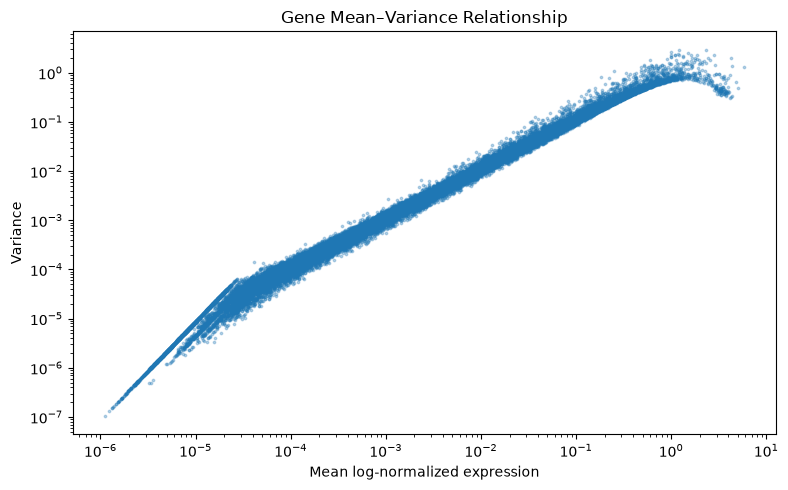

Genes with positive mean and variance: 27714


In [128]:
import matplotlib.pyplot as plt
import numpy as np

valid = (gene_means > 0) & (gene_variances > 0)

plt.figure(figsize=(8, 5))

plt.scatter(
    gene_means[valid],
    gene_variances[valid],
    s=3,
    alpha=0.3
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Mean log-normalized expression")
plt.ylabel("Variance")
plt.title("Gene Mean–Variance Relationship")

plt.tight_layout()
plt.show()

print("Genes with positive mean and variance:", valid.sum())

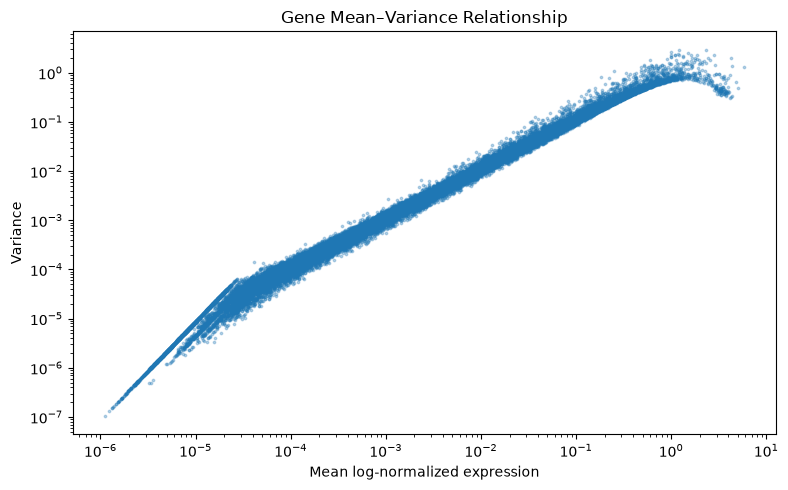

Figure saved successfully!


In [129]:
import os
import matplotlib.pyplot as plt

os.makedirs("../figures", exist_ok=True)

plt.figure(figsize=(8, 5))

plt.scatter(
    gene_means[valid],
    gene_variances[valid],
    s=3,
    alpha=0.3
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Mean log-normalized expression")
plt.ylabel("Variance")
plt.title("Gene Mean–Variance Relationship")

plt.tight_layout()

plt.savefig(
    "../figures/gene_mean_variance_relationship.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved successfully!")

In [130]:
import numpy as np
import pandas as pd

hvg_df = pd.DataFrame({
    "mean": gene_means,
    "variance": gene_variances
})

# Only genes with positive mean and variance
hvg_df = hvg_df[
    (hvg_df["mean"] > 0) &
    (hvg_df["variance"] > 0)
].copy()

# Dispersion = variance / mean
hvg_df["dispersion"] = (
    hvg_df["variance"] / hvg_df["mean"]
)

# Group genes by similar mean expression
hvg_df["mean_bin"] = pd.qcut(
    hvg_df["mean"],
    q=20,
    labels=False,
    duplicates="drop"
)

# Standardize dispersion within each group
grouped = hvg_df.groupby("mean_bin")["dispersion"]

hvg_df["normalized_dispersion"] = (
    (hvg_df["dispersion"] - grouped.transform("mean")) /
    grouped.transform("std").replace(0, np.nan)
)

print("Genes evaluated:", len(hvg_df))
print("Mean-expression groups:", hvg_df["mean_bin"].nunique())
print("Valid normalized scores:",
      hvg_df["normalized_dispersion"].notna().sum())

Genes evaluated: 27714
Mean-expression groups: 20
Valid normalized scores: 27714


In [132]:
import h5py
import numpy as np

# Select top 2000 genes
top_hvg = hvg_df.nlargest(
    2000,
    "normalized_dispersion"
).copy()

# Use gene indices because gene_ids are unavailable
gene_ids = np.array(
    [f"Gene_{i}" for i in range(29634)]
)

# Match selected genes with their IDs
top_hvg["gene_id"] = gene_ids[top_hvg.index.to_numpy()]

print("Selected HVGs:", len(top_hvg))

print("\nTop 10 Highly Variable Genes:")
print(
    top_hvg[
        ["gene_id", "mean", "variance", "normalized_dispersion"]
    ].head(10)
)

Selected HVGs: 2000

Top 10 Highly Variable Genes:
          gene_id      mean  variance  normalized_dispersion
27345  Gene_27345  0.184295  0.823957              13.030686
27346  Gene_27346  0.250933  1.068881              12.207813
24732  Gene_24732  0.081414  0.260427               9.856274
6850    Gene_6850  0.224555  0.788294               9.289502
5277    Gene_5277  0.113030  0.342023               9.028947
8459    Gene_8459  0.137819  0.438847               8.970878
25787  Gene_25787  0.134284  0.424903               8.882767
13203  Gene_13203  0.158209  0.496732               8.775091
24733  Gene_24733  0.052789  0.152698               8.748418
6632    Gene_6632  0.039998  0.114648               8.616748


In [133]:
import os

os.makedirs("../results", exist_ok=True)

hvg_save_path = "../results/top_2000_hvg.csv"

top_hvg.to_csv(
    hvg_save_path,
    index=False
)

print("HVG file saved successfully!")
print("Total selected genes:", len(top_hvg))
print("File location:", os.path.abspath(hvg_save_path))

HVG file saved successfully!
Total selected genes: 2000
File location: C:\Users\user\Desktop\lung_cancer_single_cell_tme_analysis\results\top_2000_hvg.csv


In [134]:
import numpy as np
import h5py

hvg_positions = np.sort(
    top_hvg.index.to_numpy()
)

print("Selected genes:", len(hvg_positions))
print("Unique positions:", len(np.unique(hvg_positions)))
print("First 10 positions:", hvg_positions[:10])

with h5py.File(normalized_path, "r") as f:
    print("Original matrix shape:",
          f["log1p_counts"].shape)

assert len(hvg_positions) == 2000
assert len(np.unique(hvg_positions)) == 2000

print("HVG positions verified!")

Selected genes: 2000
Unique positions: 2000
First 10 positions: [  3   4  47  52  55  77 100 148 152 196]
Original matrix shape: (29634, 86756)
HVG positions verified!


In [136]:
import h5py
import numpy as np

pca_input_path = "../data/lung_hvg_expression.h5"

with h5py.File(normalized_path, "r") as src, \
     h5py.File(pca_input_path, "w") as dst:

    expression = src["log1p_counts"]

    hvg_matrix = dst.create_dataset(
        "X",
        shape=(86756, 2000),
        dtype="float32",
        chunks=(512, 128),
        compression="gzip",
        compression_opts=4
    )

    for start in range(0, 2000, 50):
        end = min(start + 50, 2000)

        positions = hvg_positions[start:end]

        block = expression[positions, :]

        hvg_matrix[:, start:end] = block.T

        if start % 250 == 0:
            print(f"Processed {end}/2000 genes")

    src.copy("cell_ids", dst)

    selected_gene_ids = np.array(
    [f"Gene_{i}".encode("utf-8") for i in hvg_positions]
)

    dst.create_dataset(
        "gene_ids",
        data=selected_gene_ids
    )

print("HVG expression matrix saved successfully!")

Processed 50/2000 genes
Processed 300/2000 genes
Processed 550/2000 genes
Processed 800/2000 genes
Processed 1050/2000 genes
Processed 1300/2000 genes
Processed 1550/2000 genes
Processed 1800/2000 genes
HVG expression matrix saved successfully!


In [137]:
import h5py
import numpy as np
import os

with h5py.File(pca_input_path, "r") as f:

    print("Datasets:", list(f.keys()))
    print("Matrix shape:", f["X"].shape)
    print("Cell IDs:", f["cell_ids"].shape)
    print("Gene IDs:", f["gene_ids"].shape)

    sample = f["X"][:100, :100]

    print("NaN values:", np.isnan(sample).sum())
    print("Infinite values:", np.isinf(sample).sum())

    assert f["X"].shape == (86756, 2000)
    assert f["cell_ids"].shape == (86756,)
    assert f["gene_ids"].shape == (2000,)
    assert np.isfinite(sample).all()

print("HVG MATRIX VERIFICATION PASSED!")

print(
    "File size (MB):",
    round(os.path.getsize(pca_input_path) / 1024**2, 2)
)

Datasets: ['X', 'cell_ids', 'gene_ids']
Matrix shape: (86756, 2000)
Cell IDs: (86756,)
Gene IDs: (2000,)
NaN values: 0
Infinite values: 0
HVG MATRIX VERIFICATION PASSED!
File size (MB): 27.36


In [138]:
from sklearn.decomposition import IncrementalPCA
import h5py
import numpy as np

# PCA model with 50 components
ipca = IncrementalPCA(
    n_components=50,
    batch_size=1000
)

with h5py.File(pca_input_path, "r") as f:
    X = f["X"]

    for start in range(0, X.shape[0], 1000):
        end = min(start + 1000, X.shape[0])

        block = X[start:end, :].astype(np.float32)

        ipca.partial_fit(block)

        if start % 10000 == 0:
            print(f"Processed {end}/{X.shape[0]} cells")

print("PCA MODEL TRAINING COMPLETED!")
print("Components:", ipca.n_components_)

Processed 1000/86756 cells
Processed 11000/86756 cells
Processed 21000/86756 cells
Processed 31000/86756 cells
Processed 41000/86756 cells
Processed 51000/86756 cells
Processed 61000/86756 cells
Processed 71000/86756 cells
Processed 81000/86756 cells
PCA MODEL TRAINING COMPLETED!
Components: 50


In [139]:
import h5py
import numpy as np

pca_output_path = "../data/lung_pca_coordinates.h5"

with h5py.File(pca_input_path, "r") as src, \
     h5py.File(pca_output_path, "w") as dst:

    X = src["X"]

    pca_data = dst.create_dataset(
        "X_pca",
        shape=(X.shape[0], 50),
        dtype="float32"
    )

    for start in range(0, X.shape[0], 1000):
        end = min(start + 1000, X.shape[0])

        block = X[start:end, :].astype(np.float32)

        pca_data[start:end, :] = ipca.transform(block)

        if start % 10000 == 0:
            print(f"Processed {end}/{X.shape[0]} cells")

    src.copy("cell_ids", dst)

    dst.create_dataset(
        "explained_variance_ratio",
        data=ipca.explained_variance_ratio_
    )

print("PCA COORDINATES SAVED SUCCESSFULLY!")
print("PCA shape:", (86756, 50))
print(
    "Total explained variance:",
    round(ipca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

Processed 1000/86756 cells
Processed 11000/86756 cells
Processed 21000/86756 cells
Processed 31000/86756 cells
Processed 41000/86756 cells
Processed 51000/86756 cells
Processed 61000/86756 cells
Processed 71000/86756 cells
Processed 81000/86756 cells
PCA COORDINATES SAVED SUCCESSFULLY!
PCA shape: (86756, 50)
Total explained variance: 65.94 %


In [140]:
import h5py
import numpy as np

with h5py.File(pca_output_path, "r") as f:

    print("Datasets:", list(f.keys()))

    print("PCA shape:", f["X_pca"].shape)

    print("Cell IDs:", f["cell_ids"].shape)

    variance = f["explained_variance_ratio"][:]

    print(
        "Total explained variance:",
        round(variance.sum() * 100, 2),
        "%"
    )

    assert f["X_pca"].shape == (86756, 50)
    assert f["cell_ids"].shape == (86756,)
    assert len(variance) == 50

print("PCA VERIFICATION PASSED!")

Datasets: ['X_pca', 'cell_ids', 'explained_variance_ratio']
PCA shape: (86756, 50)
Cell IDs: (86756,)
Total explained variance: 65.94 %
PCA VERIFICATION PASSED!


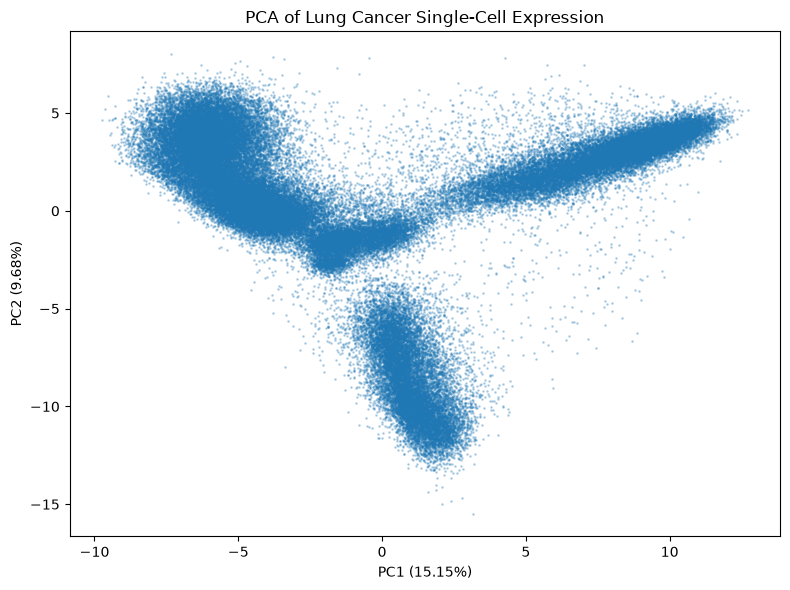

PCA figure saved successfully!


In [141]:
import h5py
import matplotlib.pyplot as plt
import os

with h5py.File(pca_output_path, "r") as f:
    pca_coords = f["X_pca"][:, :2]
    variance = f["explained_variance_ratio"][:2]

os.makedirs("../figures", exist_ok=True)

plt.figure(figsize=(8, 6))

plt.scatter(
    pca_coords[:, 0],
    pca_coords[:, 1],
    s=1,
    alpha=0.25,
    rasterized=True
)

plt.xlabel(f"PC1 ({variance[0] * 100:.2f}%)")
plt.ylabel(f"PC2 ({variance[1] * 100:.2f}%)")

plt.title("PCA of Lung Cancer Single-Cell Expression")

plt.tight_layout()

plt.savefig(
    "../figures/lung_single_cell_pca.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("PCA figure saved successfully!")

In [142]:
import h5py
import pandas as pd

with h5py.File(pca_output_path, "r") as f:
    pca_cell_ids = f["cell_ids"][:].astype(str)

print("PCA cells:", len(pca_cell_ids))
print("Annotation columns:", lung_annotation.columns.tolist())
print("First 5 PCA cell IDs:", pca_cell_ids[:5])
print("First 5 annotation IDs:")
print(lung_annotation["Index"].head().tolist())

PCA cells: 86756
Annotation columns: ['Index', 'Barcode', 'Sample', 'Sample_Origin', 'Cell_type', 'Cell_type.refined', 'Cell_subtype']
First 5 PCA cell IDs: ['AAACCTGAGAAGGTGA_LUNG_N18' 'AAACCTGAGACAAAGG_LUNG_N18'
 'AAACCTGAGACCTTTG_LUNG_N30' 'AAACCTGAGACGACGT_LUNG_T09'
 'AAACCTGAGACGACGT_LUNG_T34']
First 5 annotation IDs:
['AAACCTGCAAGGTGTG_LUNG_N01', 'AACTCCCGTTCACCTC_LUNG_N01', 'AACTCCCTCACGCGGT_LUNG_N01', 'AAGGAGCGTGTGCGTC_LUNG_N01', 'AAGGTTCAGGTACTCT_LUNG_N01']


In [143]:
# Check duplicate annotation IDs
print(
    "Duplicate annotation IDs:",
    lung_annotation["Index"].duplicated().sum()
)

# Match annotations using PCA cell order
pca_metadata = (
    lung_annotation
    .set_index("Index")
    .reindex(pca_cell_ids)
)

print("PCA cells:", len(pca_cell_ids))

print(
    "Matched annotations:",
    pca_metadata["Cell_type"].notna().sum()
)

print(
    "Missing annotations:",
    pca_metadata["Cell_type"].isna().sum()
)

print("\nCell type counts:")
print(pca_metadata["Cell_type"].value_counts())

Duplicate annotation IDs: 0
PCA cells: 86756
Matched annotations: 86756
Missing annotations: 0

Cell type counts:
Cell_type
T lymphocytes        29614
Myeloid cells        25193
Epithelial cells     10230
NK cells              7818
B lymphocytes         5690
Fibroblasts           3351
MAST cells            2883
Endothelial cells     1977
Name: count, dtype: int64


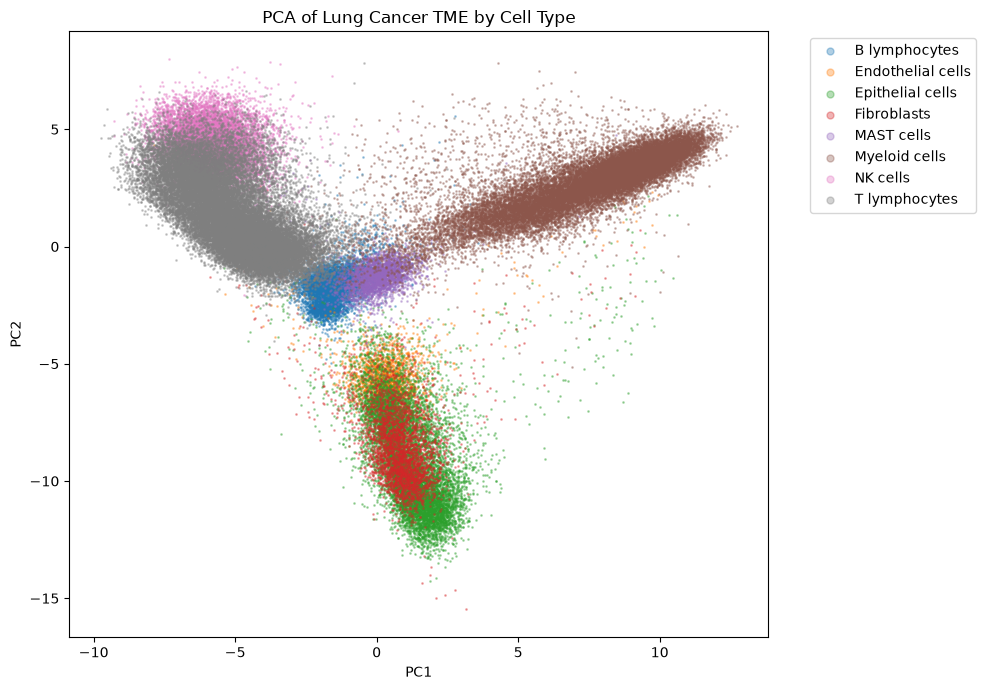

Cell-type PCA figure saved successfully!


In [144]:
import matplotlib.pyplot as plt
import numpy as np
import os

cell_types = pca_metadata["Cell_type"].to_numpy()
unique_types = sorted(np.unique(cell_types))

colors = plt.get_cmap("tab10")

plt.figure(figsize=(10, 7))

for i, cell_type in enumerate(unique_types):

    mask = cell_types == cell_type

    plt.scatter(
        pca_coords[mask, 0],
        pca_coords[mask, 1],
        s=1,
        alpha=0.35,
        color=colors(i),
        label=cell_type,
        rasterized=True
    )

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA of Lung Cancer TME by Cell Type")

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    markerscale=5
)

plt.tight_layout()

os.makedirs("../figures", exist_ok=True)

plt.savefig(
    "../figures/pca_by_cell_type.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Cell-type PCA figure saved successfully!")

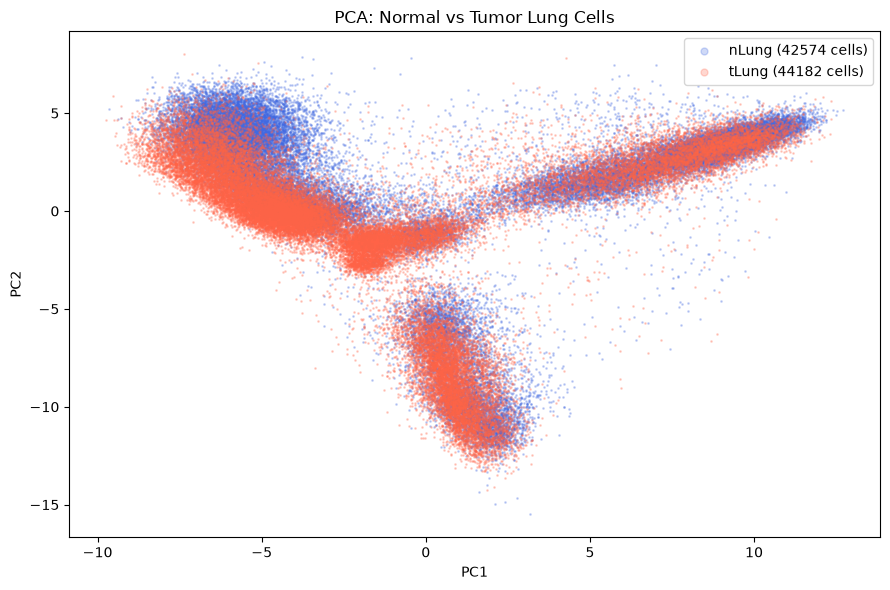

Normal vs Tumor PCA saved!


In [145]:
import matplotlib.pyplot as plt
import numpy as np

origins = pca_metadata["Sample_Origin"].to_numpy()

plt.figure(figsize=(9, 6))

for group, color in [
    ("nLung", "royalblue"),
    ("tLung", "tomato")
]:
    mask = origins == group

    plt.scatter(
        pca_coords[mask, 0],
        pca_coords[mask, 1],
        s=1,
        alpha=0.25,
        color=color,
        label=f"{group} ({mask.sum()} cells)",
        rasterized=True
    )

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA: Normal vs Tumor Lung Cells")
plt.legend(markerscale=5)
plt.tight_layout()

plt.savefig(
    "../figures/pca_normal_vs_tumor.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Normal vs Tumor PCA saved!")

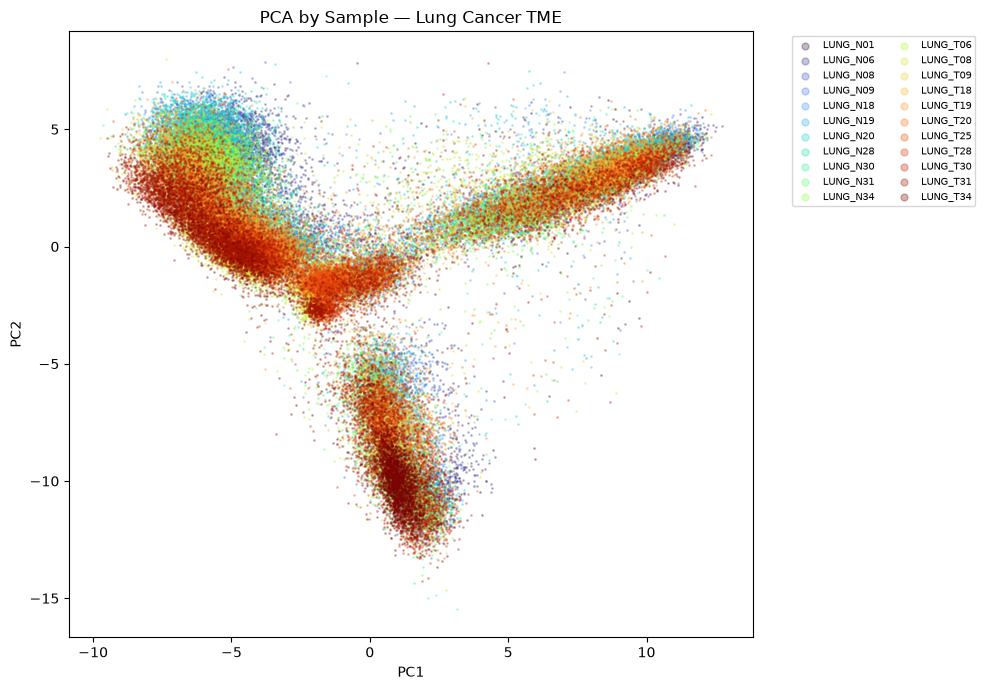

Sample-wise PCA saved!
Total samples: 22


In [146]:
import matplotlib.pyplot as plt
import numpy as np

samples = pca_metadata["Sample"].to_numpy()
unique_samples = sorted(np.unique(samples))

plt.figure(figsize=(10, 7))

colors = plt.get_cmap("turbo", len(unique_samples))

for i, sample in enumerate(unique_samples):
    mask = samples == sample

    plt.scatter(
        pca_coords[mask, 0],
        pca_coords[mask, 1],
        s=1,
        alpha=0.3,
        color=colors(i),
        label=sample,
        rasterized=True
    )

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA by Sample — Lung Cancer TME")

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    fontsize=7,
    markerscale=5,
    ncol=2
)

plt.tight_layout()

plt.savefig(
    "../figures/pca_by_sample.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Sample-wise PCA saved!")
print("Total samples:", len(unique_samples))

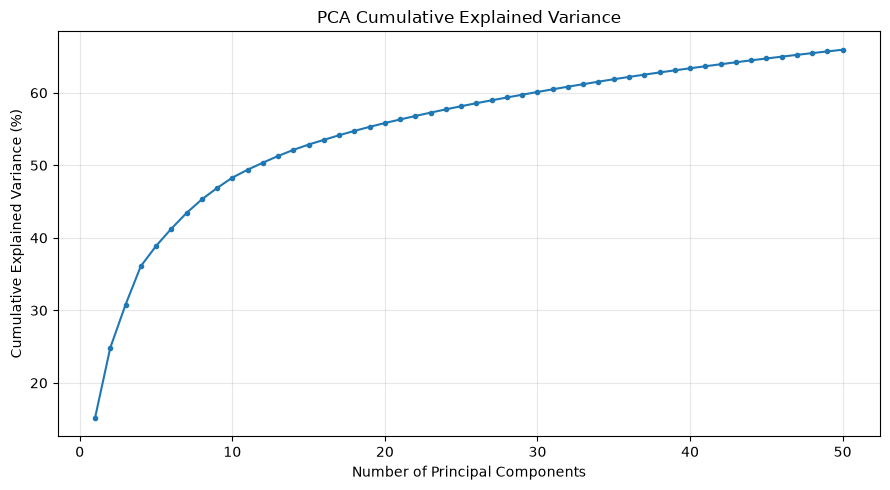

Variance explained by first 20 PCs: 55.83 %
Variance explained by first 30 PCs: 60.12 %
Variance explained by all 50 PCs: 65.94 %
Figure saved successfully!


In [147]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

with h5py.File(pca_output_path, "r") as f:
    explained = f["explained_variance_ratio"][:]

cumulative = np.cumsum(explained) * 100

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, 51),
    cumulative,
    marker="o",
    markersize=3
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("PCA Cumulative Explained Variance")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../figures/pca_cumulative_variance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Variance explained by first 20 PCs:",
      round(cumulative[19], 2), "%")

print("Variance explained by first 30 PCs:",
      round(cumulative[29], 2), "%")

print("Variance explained by all 50 PCs:",
      round(cumulative[49], 2), "%")

print("Figure saved successfully!")

In [148]:
import h5py
import numpy as np

with h5py.File(pca_output_path, "r") as f:
    print("Available datasets:", list(f.keys()))

    for name in f.keys():
        print(name, ":", f[name].shape)

Available datasets: ['X_pca', 'cell_ids', 'explained_variance_ratio']
X_pca : (86756, 50)
cell_ids : (86756,)
explained_variance_ratio : (50,)
